<center>

### **Predicting Reddit Post Popularity: A Comparison of Title-Only and Content-Aware Models**
</center>


---



## Table of Contents

- [0. Prerequisites](#0.-Prerequisites)
  - [0.1 Import Packages](#0.1-Import-Packages)
  - [0.2 Download Preprocessed Datasets](#0.2-Download-Preprocessed-Datasets)
- [1. Abstract](#1.-Abstract)
- [2. Introduction](#2.-Introduction)
- [3. Related Work](#3.-Related-Work)
- [4. Dataset](#4.-Dataset)
- [5. Methods](#5.-Methods)
  - [5.1 Metrics](#5.1-Metrics)
  - [5.2 Data Preprocessing](#5.2-Data-Preprocessing)
- [6. Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
- [7. Baseline Models](#7.-Baseline-Models)
  - [7.1 Feature Setup](#7.1-Feature-Setup)
  - [7.2 Dummy Regressor](#7.2-Dummy-Regressor)
  - [7.3 Ridge Regression](#7.3-Ridge-Regression)
  - [7.4 Random Forest Regressor](#7.4-Random-Forest-Regressor)
  - [7.5 Baseline Comparison](#7.5-Baseline-Comparison)
  - [7.6 Feature Importance](#7.6-Feature-Importance)
- [8. DistilBERT Hybrid Models](#8.-DistilBERT-Hybrid-Models)
  - [8.1 Data Preparation](#8.1-Data-Preparation)
    - [8.1.1 Metadata Normalization](#8.1.1-Metadata-Normalization)
    - [8.1.2 Tokenizer](#8.1.2-Tokenizer)
      - [8.1.2.1 Tokenization Example](#8.1.2.1-Tokenization-Example)
  - [8.1.3 Token Length Analysis](#8.1.3-Token-Length-Analysis)
    - [8.1.3.1 Title-Only Length](#8.1.3.1-Title-Only-Length)
    - [8.1.3.2 Title + Content Length](#8.1.3.2-Title-+-Content-Length)
  - [8.1.4 Dataset Classes](#8.1.4-Dataset-Classes)
  - [8.2 Model Architecture](#8.2-Model-Architecture)
    - [8.2.1 Freezing Strategy](#8.2.1-Freezing-Strategy)
  - [8.3 Training Setup](#8.3-Training-Setup)
    - [8.3.1 Custom Optimizer](#8.3.1-Custom-Optimizer)
    - [8.3.2 Training Configuration](#8.3.2-Training-Configuration)
    - [8.3.3 Logging Setup](#8.3.3-Logging-Setup)
  - [8.4 Model 1: Title + Metadata](#8.4-Model-1:-Title-+-Metadata)
  - [8.4.1 Evaluation: Title + Metadata Model](#8.4.1-Evaluation:-Title-+-Metadata-Model)
  - [8.5 Model 2: Content-Aware (Title + Content + Metadata)](#8.5-Model-2:-Content-Aware-(Title-+-Content-+-Metadata))
  - [8.5.1 Evaluate: Content-Aware Model](#8.5.1-Evaluate:-Content-Aware-Model)
  - [8.6 BERT Metadata Feature Importance](#8.6-BERT-Metadata-Feature-Importance)
- [9. Results](#9.-Results)
  - [9.1 Predicted vs Actual](#9.1-Predicted-vs-Actual)
  - [9.2 Error Distribution](#9.2-Error-Distribution)
- [10. Discussion](#10.-Discussion)
- [11. Conclusion and Future Work](#11.-Conclusion-and-Future-Work)
- [12. Final Evaluation on Test Set](#12.-Final-Evaluation-on-Test-Set)
- [13. Prediction Demo](#13.-Prediction-Demo)
  - [13.1 Random Sample Predictions](#13.1-Random-Sample-Predictions)
  - [13.2 Timing Experiment](#13.2-Timing-Experiment)
  - [13.3 Title Rewriting Experiment](#13.3-Title-Rewriting-Experiment)
- [14. References](#14.-References)

## 0. Prerequisites

This section sets up all dependencies and seeds before any data or model code runs. Reproducibility seeds are placed here at the very top of the notebook to ensure they take effect before any random operations occur, including dataset splits, model weight initialization, and data shuffling. If seeds are set after any of these operations, they have no effect on those earlier steps.

### Reproducibility Guide

This notebook supports three dataset sizes for experimentation:

| Size | Training Posts | Approx. BERT Training Time (T4 GPU) |
|---|---|---|
| `"small"` | 78,750 | ~10–25 min per model |
| `"medium"` | 157,500 | ~30–50 min per model |
| `"full"` | 315,000 | ~60–90 min per model |

To switch dataset size, change one line in Cell 5:

```python
train_df, val_df, test_df = load_dataset("medium")  # change to "small" or "full"
```

All results in this notebook are based on the medium dataset. To reproduce them, run all cells top to bottom without modification on a Colab L4 GPU. Results have been verified to be reproducible to 4 decimal places across multiple runs on the same hardware. Minor variance of ±0.01 may occur on different GPU hardware such as a T4, due to differences in fp16 floating point execution between GPU architectures. A Colab T4 GPU or better is strongly recommended as local CPU training will extend training time by approximately 2 to 2.5 times.

### 0.1 Import Packages

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import ParameterGrid

import torch
import torch.nn as nn
from torch.utils.data import Dataset
from transformers import DistilBertTokenizer, DistilBertModel, Trainer, TrainingArguments, EarlyStoppingCallback, TrainerCallback

import gdown
import warnings

for w in [RuntimeWarning, UserWarning]:  # suppress HuggingFace auth token warnings
    warnings.filterwarnings("ignore", category=w)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True  # ensures deterministic CUDA operations
torch.backends.cudnn.benchmark = False # disables auto-tuning which is non-deterministic



> **Note:** The global seed set here applies to all model training and data operations. In Section 13, a separate seed is set manually for the prediction demo. This was done to ensure the displayed Reddit posts are appropriate and do not contain offensive or sensitive content.


### 0.2 Download Preprocessed Datasets

The raw Reddit data was processed using a custom [**streaming pipeline** ](https://github.com/thameem-a/COMP-432-Project/blob/main/project/processing_pipline.ipynb) to avoid loading the entire compressed `.zst` file into memory at once. Posts with missing titles or marked as deleted were filtered out during this step.

Because Reddit upvote distributions are highly skewed most posts receive very few upvotes while a small number go viral, a **stratified sampling strategy** was used. Posts were grouped into four bins: **zero (≤0)**, **low (1–10)**, **mid (11–100)**, and **high (>100)**. Each bin was capped at a maximum number of samples to prevent low-score posts from dominating the dataset.

The data was then split into **training (70%)**, **validation (15%)**, and **test (15%)** sets, with splits assigned randomly within each bin. This ensures all three splits have a consistent distribution of post popularity verified in Figure 1.

**Full Dataset:**

| Dataset | File Name | URL | File Size | Posts | Approx. Training Time |
|---|---|---|---|---|---|
| Train | train.jsonl | [Download](https://drive.google.com/file/d/19bl8To8UT7b3ysL-3jHbFQWvdebzKhZk/view?usp=sharing) | 193.9 MB | 315,000 | ~60–90 min per BERT model (T4) |
| Validation | val.jsonl | [Download](https://drive.google.com/file/d/1_ZlBWQLJbkOOBMtJTU4G1iNacF-KCwy4/view?usp=sharing) | 41.7 MB | 67,500 | — |
| Test | test.jsonl | [Download](https://drive.google.com/file/d/1al-vkWjR5gGBBoI8bbGM7dBTLQF8kBIC/view?usp=sharing) | 41.1 MB | 67,500 | — |

**Medium Subset:**

| Dataset | File Name | URL | File Size | Posts | Approx. Training Time |
|---|---|---|---|---|---|
| Train | train_medium.jsonl | [Download](https://drive.google.com/file/d/1mHDbI13vo091D2zP0ywTbhHGqYkUy9ld/view?usp=drive_link) | 96.8 MB | 157,500 | ~30–50 min per BERT model (T4) |
| Validation | val_medium.jsonl | [Download](https://drive.google.com/file/d/1ZDK9f4P-vzv7CNRZLfBa38qArYyQz6DX/view?usp=drive_link) | 41.7 MB | 33,750 | — |
| Test | test_medium.jsonl | [Download](https://drive.google.com/file/d/1_4lrXlbHXRNoT_gGjDnsCT0fsSQG8Ymn/view?usp=drive_link) | 41.1 MB | 33,750 | — |

**Small Subset:**

| Dataset | File Name | URL | File Size | Posts | Approx. Training Time |
|---|---|---|---|---|---|
| Train | train_small.jsonl | [Download](https://drive.google.com/file/d/1W8UzCSIOLgPOOym8SLz2oKOtqD95fyAn/view?usp=drive_link) | 48.7 MB | 78,750 | ~10–25 min per BERT model (T4) |
| Validation | val_small.jsonl | [Download](https://drive.google.com/file/d/1b5837J1pddjxEbeofdohgxN9qv8Xpwv3/view?usp=drive_link) | 10.4 MB | 16,875 | — |
| Test | test_small.jsonl | [Download](https://drive.google.com/file/d/1rylfzZy7SRx_K6QvLOAs_kErHhT8Pq18/view?usp=drive_link) | 10.4 MB | 16,875 | — |

In [40]:
FOLDER = {
    "full": {
        "train": "19bl8To8UT7b3ysL-3jHbFQWvdebzKhZk",
        "val": "1_ZlBWQLJbkOOBMtJTU4G1iNacF-KCwy4",
        "test": "1al-vkWjR5gGBBoI8bbGM7dBTLQF8kBIC"
    },
    "medium": {
        "train": "1mHDbI13vo091D2zP0ywTbhHGqYkUy9ld",
        "val": "1ZDK9f4P-vzv7CNRZLfBa38qArYyQz6DX",
        "test": "1_4lrXlbHXRNoT_gGjDnsCT0fsSQG8Ymn"
    },
    "small": {
        "train": "1W8UzCSIOLgPOOym8SLz2oKOtqD95fyAn",
        "val": "1b5837J1pddjxEbeofdohgxN9qv8Xpwv3",
        "test": "1rylfzZy7SRx_K6QvLOAs_kErHhT8Pq18"
    }
}

def download_file(file_id, output_path):
  """
  Download a file from Google Drive if it does not already exist locally.

  Args:
      file_id (str): The Google Drive file ID to download.
      output_path (str): The local path where the file will be saved.

  Returns:
      None

  Example:
      >>> download_file("1mHDbI13vo091D2zP0ywTbhHGqYkUy9ld", "data/medium/train.jsonl")
      Downloading data/medium/train.jsonl...
  """
  if not os.path.exists(output_path):
        url = f"https://drive.google.com/uc?id={file_id}"
        print(f"Downloading {output_path}...")
        gdown.download(url, output_path, quiet=False)
  else:
        print(f"{output_path} already exists.")

def load_dataset(size="medium"):
    """
    Download and load train, validation, and test splits for a given dataset size.

    Args:
        size (str): Dataset size to load. One of "small", "medium", or "full". Defaults to "medium".

    Returns:
        tuple: (train_df, val_df, test_df) as pandas DataFrames, each containing post title, content, score, log_score, and 12 metadata features.

    Example:
        >>> train_df, val_df, test_df = load_dataset("small")
        Loading 'small' dataset from data/small/...
        Train: 78,750
        Val: 16,875
        Test: 16,875
    """
    if size not in FOLDER:
        raise ValueError(f"Invalid size '{size}'. Choose from: {list(FOLDER)}")

    base = f"data/{size}"
    os.makedirs(base, exist_ok=True)

    for split_name, file_id in FOLDER[size].items():
        if file_id.strip():
            download_file(file_id.strip(), f"{base}/{split_name}.jsonl")

    print(f"Loading '{size}' dataset from {base}/...")

    train_df = pd.read_json(f"{base}/train.jsonl", lines=True)
    val_df = pd.read_json(f"{base}/val.jsonl", lines=True)
    test_df  = pd.read_json(f"{base}/test.jsonl", lines=True)

    print(f"Train: {len(train_df):,}")
    print(f"Val: {len(val_df):,}")
    print(f"Test: {len(test_df):,}")

    return train_df, val_df, test_df

# To switch dataset size, change "medium" to "small" or "full"
train_df, val_df, test_df = load_dataset("medium")

data/medium/train.jsonl already exists.
data/medium/val.jsonl already exists.
data/medium/test.jsonl already exists.
Loading 'medium' dataset from data/medium/...
Train: 157,133
Val: 33,809
Test: 33,809


---
## 1. Abstract



Social media platforms like Reddit have become powerful drivers of public opinion, consumer behavior, and even financial markets. The **r/wallstreetbets** movement is a good example, where a series of posts on a single thread triggered remarkable real-world economic consequences (e.g. GameStop stock in 2021).

Being able to predict which posts will gain traction before they are published would allow researchers, platforms, and communities to better anticipate emerging trends and understand the dynamics of online virality.

In this project, I develop a machine learning system capable of predicting the popularity of a Reddit post at the moment of publication, measured by the number of upvotes it receives. I compare five models of increasing complexity: a Dummy Regressor, Ridge Regression, Random Forest, and two hybrid DistilBERT architectures that combine transformer-based text understanding with structured metadata.

The title-only BERT model achieves a validation RMSE of **1.3891**, while the content-aware variant, which additionally incorporates post body text, achieves **1.3717**, both substantially outperforming the Random Forest baseline of **1.4650**.

These results confirm that language understanding adds meaningful predictive signal beyond metadata alone, and that post body text carries additional information that improves prediction for posts that include it.

---



## 2. Introduction

Reddit is one of the largest creator-driven social media platforms, where users submit posts across thousands of communities called *subreddits*, each with its own norms and audience. The popularity of these posts, typically measured by upvotes, determines content visibility, algorithmic ranking, and the formation of online trends. Accurately predicting which posts will gain traction before publication is valuable for understanding user engagement, improving recommendation systems, and analyzing the dynamics of online virality.

Predicting post popularity is inherently difficult. Engagement is influenced by a combination of factors, including textual content, posting time, and subreddit-specific behavior. Posts with similar structure or topic can receive vastly different levels of attention. For example, a short title-only post may receive thousands of upvotes, while a detailed long-form post receives little engagement. This variability makes the task a challenging regression problem.

As shown in Figure 1, the distribution of post upvotes is highly skewed. Over 53% of posts receive zero upvotes, while only a small fraction exceed 1,000. This long-tailed distribution reflects the nature of online virality and complicates the learning process. To address this, a log transformation is applied to the target variable, compressing the scale and producing a more tractable regression target.

In this project, I develop a machine learning system to predict Reddit post popularity using both textual and structured features. I use **DistilBERT** (Sanh et al., 2019), a transformer-based language model capable of capturing contextual meaning in text, and combine it with metadata features in a hybrid architecture. I compare two variants: a **title + metadata model** and a **content-aware model** that additionally incorporates post body text. This controlled comparison directly addresses the central research question of the project: *does including post body text beyond the title improve popularity prediction?*


---



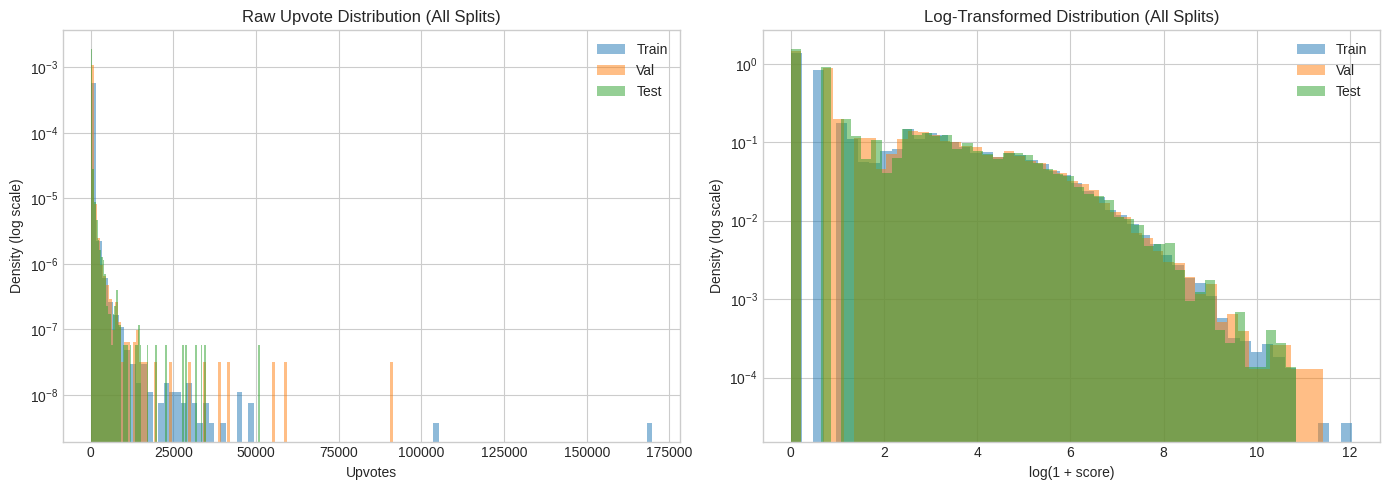

In [41]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_df["score"], bins=100, alpha=0.5, label="Train", density=True)
axes[0].hist(val_df["score"], bins=100, alpha=0.5, label="Val", density=True)
axes[0].hist(test_df["score"], bins=100, alpha=0.5, label="Test", density=True)
axes[0].set_yscale("log")
axes[0].set_title("Raw Upvote Distribution (All Splits)")
axes[0].set_xlabel("Upvotes")
axes[0].set_ylabel("Density (log scale)")
axes[0].legend()

axes[1].hist(train_df["log_score"], bins=50, alpha=0.5, label="Train", density=True)
axes[1].hist(val_df["log_score"], bins=50, alpha=0.5, label="Val",   density=True)
axes[1].hist(test_df["log_score"], bins=50, alpha=0.5, label="Test",  density=True)
axes[1].set_yscale("log")
axes[1].set_title("Log-Transformed Distribution (All Splits)")
axes[1].set_xlabel("log(1 + score)")
axes[1].set_ylabel("Density (log scale)")
axes[1].legend()

os.makedirs("figures", exist_ok=True)
plt.tight_layout()
plt.show()



> <p><strong>Figure 1:</strong> Distribution of Reddit post upvotes across training, validation, and test splits. Left: the raw upvote distribution is extremely right-skewed. Right: after applying log(1 + score), the distribution becomes more symmetric and suitable for regression. The similarity across splits confirms that stratified sampling preserved the underlying distribution.</p>



---
## 3. Related Work

Early work on Reddit popularity prediction primarily relied on traditional machine learning approaches. Segall and Zamoshchin [[1]](https://cs229.stanford.edu/proj2012/ZamoshchinSegall-PredictingRedditPostPopularity.pdf) framed the problem as a binary classification task, using subreddit metadata and bag-of-words features derived from post titles to predict whether a post would be popular. While effective for coarse-grained prediction, this approach reduces a continuous engagement signal to a binary label, leading to a loss of information. Additionally, bag-of-words representations ignore word order and context, limiting their ability to capture nuanced linguistic patterns.Reevesman et al. [[2]](https://medium.com/data-science/predicting-reddit-comment-karma-a8f570b544fc) explored random forest regression for predicting Reddit comment karma, demonstrating that ensemble tree methods can model non-linear interactions between features. However, their work focused on comment-level prediction rather than post-level popularity and did not incorporate deep semantic understanding of text.Kim [[3]](https://arxiv.org/abs/2106.07380) conducted a broader comparison of linear regression, random forests, and neural networks for Reddit post popularity prediction. Their findings showed that neural network-based models outperform traditional methods when textual features are included, highlighting the importance of richer feature representations. Notably, this work identifies transformer-based models as a promising direction for capturing deeper semantic information.A key limitation across these prior approaches is the reliance on shallow text representations such as TF-IDF or bag-of-words, which treat words as independent tokens and fail to capture contextual relationships. Transformer-based models such as BERT (Devlin et al., 2019) [[4]](https://arxiv.org/abs/1810.04805) address this limitation by leveraging self-attention mechanisms to encode the contextual meaning of each word relative to the entire sequence. This enables significantly richer and more expressive representations of text, making them well-suited for tasks involving nuanced language understanding, such as predicting post popularity.


## 4. Dataset

The dataset is derived from the Reddit submission corpus available via [Academic Torrents (Pushshift)](https://academictorrents.com/details/8412b89151101d88c915334c45d9c223169a1a60). The final dataset contains 450,000 posts split into training (315,000),
validation (67,500), and test (67,500) sets. Each post includes the following fields:

**`title`** : the post title, used as the primary text input to both BERT models.

**`content`** : the post body text, used as additional input to the content-aware model.

**`score`** : the raw upvote count.

**`log_score`** : `log(1 + score)`, the regression target used for all models.

**12 metadata features** : structured features available at the exact moment of posting:

| Feature | Description |
|---|---|
| `has_content` | Whether the post has a body beyond the title |
| `nsfw` | Whether the post is marked as adult content |
| `is_self` | Whether it is a self-post (text) vs. link post |
| `hour` | Hour of day the post was submitted |
| `day_of_week` | Day of week (0=Monday, 6=Sunday) |
| `is_weekend` | Whether the post was submitted on a weekend |
| `title_length` | Number of words in the title |
| `char_length` | Number of characters in the title |
| `uppercase_ratio` | Proportion of uppercase characters |
| `num_exclamations` | Number of exclamation marks |
| `num_questions` | Number of question marks |
| `content_length` | Length of post body in characters |

All features are strictly limited to what is available at posting time. No
post-publication signals such as number of comments or upvote ratio are included, ensuring the model is a genuine pre-publication predictor rather than a retrospective
analysis.



---



## 5. Methods

### 5.1 Metrics

The primary metric used to evaluate every model is Root Mean Squared Error (RMSE), defined as:

$$
\mathrm{RMSE} = \sqrt{\mathrm{MSE}}, \qquad \mathrm{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$

where $y_i$ is the true $\log(1 + \text{score})$ value for post $i$ and $\hat{y}_i$ is the model's prediction.

RMSE is appropriate for this task because the target is continuous after the log transformation, and squared-error penalization disproportionately punishes large prediction errors, matching the practical cost of misprediction. Using RMSE consistently across all five models also enables direct comparison.

I additionally report **Mean Absolute Error (MAE)** for the BERT models, defined as:

$$
\mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$

MAE is more robust to outlier viral posts than RMSE and provides a directly interpretable measure of average prediction error in log-score units. It is reported only for the BERT models because these are the models of primary interest in our comparison, and MAE serves as a secondary confirmation that the observed RMSE improvements are not driven by a handful of lucky outlier predictions. The baseline models are evaluated on RMSE alone since their purpose is to establish the performance floor against which the BERT models are measured, and a single consistent metric is sufficient for that role.

### 5.2 Data Preprocessing

The dataset was cleaned during the preprocessing pipeline described in Section 0.2. Key steps applied upstream include filtering invalid posts, stratified sampling across four score bins, applying `log_score = log(1 + score)`, and engineering the 12 metadata features. No additional cleaning is required here.

The one preprocessing step applied within this notebook is **metadata normalization** for the DistilBERT models, described in Section 8.1. This is necessary because DistilBERT embeddings and raw metadata features operate on different numerical scales without normalization, the regression head would disproportionately weight raw metadata values over text embeddings.



---



## 6. Exploratory Data Analysis

The raw upvote distribution is extremely right-skewed (Figure 1, Section 2): most posts receive very few upvotes while a small number go viral. Applying log(1 + score) symmetrizes the distribution and prevents high-upvote outliers from dominating the loss function during training. Near-identical distributions across train, validation, and test splits confirm that stratified sampling preserved the population shape, meaning RMSE scores are representative of real-world performance on unseen posts.

Content availability varies across the dataset: roughly 47% of posts include body text while 53% are title-only. Since the has_content flag captures this distinction, it is retained as a binary feature posts with body text are encoded as 1, title-only posts as 0.



In [42]:
n_with = (train_df["content"] != "").sum()
n_without = (train_df["content"] == "").sum()
total = len(train_df)

print(f"Posts with body text: {n_with:>6,} ({n_with/total:.1%})")
print(f"Posts without body text: {n_without:>6,} ({n_without/total:.1%})")

# Ensure has_content is a clean binary flag (0 / 1), not a scaled float
train_df["has_content"] = (train_df["content"] != "").astype(int)

print("\nhas_content distribution (after binarization):")
print(train_df["has_content"]
    .value_counts()
    .rename({1: "has body text", 0: "title-only"})
    .to_frame("count")
    .assign(pct=lambda df: (df["count"] / total * 100).round(1).astype(str) + "%")
)

Posts with body text: 74,822 (47.6%)
Posts without body text: 82,311 (52.4%)

has_content distribution (after binarization):
               count    pct
has_content                
title-only     82311  52.4%
has body text  74822  47.6%


---


## 7. Baseline Models

Before introducing the DistilBERT-based models, I establish baseline performance using three traditional machine learning approaches: a Dummy Regressor, Ridge Regression, and a Random Forest. All baseline models rely exclusively on the 12 structured metadata features and do not incorporate any textual information from the post title or body.

This design choice is intentional, as it isolates the contribution of textual understanding. By comparing these metadata-only models against transformer-based approaches, I can directly quantify the added predictive value of language modeling.

All models are evaluated on the validation set using Root Mean Squared Error (RMSE). The test set is held out until the final evaluation (Section 12) to prevent information leakage and ensure a fair comparison across models.

### 7.1 Feature Setup

The 12 metadata features are extracted from the dataframes and split into train, validation, and test arrays. These same features are later used as the metadata input to both hybrid BERT models, ensuring a fair comparison.

In [43]:
features = [
    "has_content", "nsfw", "is_self",
    "hour", "day_of_week", "is_weekend",
    "title_length", "char_length",
    "uppercase_ratio", "num_exclamations",
    "num_questions", "content_length"
]

X_train = train_df[features]
y_train = train_df["log_score"]
X_val = val_df[features]
y_val = val_df["log_score"]
X_test = test_df[features]
y_test = test_df["log_score"]

### 7.2 Dummy Regressor

The Dummy Regressor predicts the mean `log_score` of the training set for every post, completely ignoring all input features. It represents a zero-effort baseline, any model that cannot beat this is not extracting useful information from the data. It sets the performance floor against which all other models are compared.

In [44]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

y_pred_dummy = dummy.predict(X_val)
dummy_rmse = np.sqrt(mean_squared_error(y_val, y_pred_dummy))

print(f"Dummy RMSE: {dummy_rmse:.4f}")

Dummy RMSE: 1.9398


### 7.3 Ridge Regression

Ridge Regression is a linear model that learns a weighted combination of the 12 metadata features to predict `log_score`. The L2 ridge penalty adds a small cost for large weights, which helps when features are correlated. For example, `title_length` (word count) and `char_length` (character count) carry overlapping information.

Feature scaling is applied before training since Ridge Regression is sensitive to the magnitude of input values. The `StandardScaler` is fit **only on the training set** and then applied to the validation and test sets to prevent data leakage. Fitting the scaler on all data would allow training to benefit from knowledge of the validation and test distributions.

Ridge has one hyperparameter, `alpha`, which controls the strength of the L2 penalty. Larger values penalize coefficients more aggressively, reducing overfitting at the cost of potential underfitting. I sweep over a logarithmic range of alpha values from 0.001 to 1000, which is the standard approach for Ridge tuning [6], and select the value that minimizes validation RMSE.

The sweep showed that validation RMSE is essentially constant (1.6918) across all alpha values, varying only at the fourth decimal place. This is expected given the problem structure. With 157,133 training samples and only 12 features, there are roughly 13,000 samples per parameter, which means the ordinary least squares solution is already well-conditioned and the regularization penalty is negligible relative to the MSE term. This result reflects the ceiling of linear modeling on 12 metadata features rather than a failure of tuning, and it motivates the non-linear and text-based models that follow.

In [45]:
ridge_scaler = StandardScaler()
X_train_scaled = ridge_scaler.fit_transform(X_train)
X_val_scaled = ridge_scaler.transform(X_val)

alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_results = []

for alpha in alphas:
    r = Ridge(alpha=alpha)
    r.fit(X_train_scaled, y_train)
    preds = r.predict(X_val_scaled)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    ridge_results.append((rmse, alpha))
    print(f"alpha={alpha:>8} | RMSE: {rmse:.4f}")

ridge_results.sort(key=lambda x: x[0])
ridge_rmse, best_alpha = ridge_results[0]

print(f"\nBest Ridge alpha: {best_alpha}")
print(f"Best Ridge RMSE: {ridge_rmse:.4f}")


alpha=   0.001 | RMSE: 1.6918
alpha=    0.01 | RMSE: 1.6918
alpha=     0.1 | RMSE: 1.6918
alpha=     1.0 | RMSE: 1.6918
alpha=    10.0 | RMSE: 1.6918
alpha=   100.0 | RMSE: 1.6918
alpha=  1000.0 | RMSE: 1.6919

Best Ridge alpha: 10.0
Best Ridge RMSE: 1.6918


In [46]:
# Refit the best Ridge model
ridge = Ridge(alpha=best_alpha)
ridge.fit(X_train_scaled, y_train)

Ridge(alpha=10.0)

### 7.4 Random Forest Regressor

A Random Forest [7] builds many decision trees independently on random subsets of the data and averages their predictions. Unlike Ridge Regression, it can capture **non-linear relationships** between features. For example, a high `uppercase_ratio` may only signal virality when combined with certain posting hours. It also does not require feature scaling since trees split based on rank order rather than absolute magnitude.

Random Forest has several hyperparameters that meaningfully affect performance [8]. I performed a grid search over `n_estimators` (number of trees), `max_depth` (maximum tree depth), `min_samples_split` (minimum samples required to split a node), and `max_features` (number of features considered at each split). This produces 24 configurations, each evaluated on the validation set. Unbounded trees (`max_depth=None`) were excluded based on preliminary experiments, which showed they consistently overfit on this dataset.

In [47]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", 0.5, 1.0],
}

results = []

for params in ParameterGrid(param_grid):
    rf = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=-1,
    )
    rf.fit(X_train, y_train)
    preds = rf.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    results.append((rmse, params))
    print(f"RMSE: {rmse:.4f} | {params}")

results.sort(key=lambda x: x[0])
best_rmse, best_params = results[0]

print("\nTop 5 configurations\n")
for rmse, params in results[:5]:
    print(f" {rmse:.4f}  {params}")

print(f"\nBest RF Params: {best_params}")
print(f"Best RF RMSE: {best_rmse:.4f}")

RMSE: 1.4839 | {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
RMSE: 1.4830 | {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 200}
RMSE: 1.4866 | {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
RMSE: 1.4858 | {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 200}
RMSE: 1.4685 | {'max_depth': 10, 'max_features': 0.5, 'min_samples_split': 2, 'n_estimators': 100}
RMSE: 1.4687 | {'max_depth': 10, 'max_features': 0.5, 'min_samples_split': 2, 'n_estimators': 200}
RMSE: 1.4693 | {'max_depth': 10, 'max_features': 0.5, 'min_samples_split': 5, 'n_estimators': 100}
RMSE: 1.4689 | {'max_depth': 10, 'max_features': 0.5, 'min_samples_split': 5, 'n_estimators': 200}
RMSE: 1.4708 | {'max_depth': 10, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 100}
RMSE: 1.4708 | {'max_depth': 10, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200

In [48]:
# Refit the best model
rf_best = RandomForestRegressor(**best_params, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)
rf_rmse = best_rmse

The heatmap below visualizes how validation RMSE varies with `max_depth` and `max_features`, the two most influential hyperparameters. Values are averaged across `n_estimators` and `min_samples_split` to isolate the effect of these two parameters.

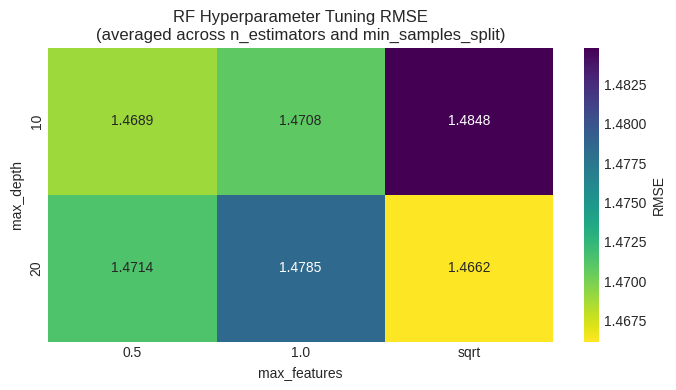

In [49]:
# Hyperparameter tuning visualization max_features × max_depth
df_results = pd.DataFrame([{**params, "rmse": rmse} for rmse, params in results])
df_results["max_depth"] = df_results["max_depth"].astype(str)

pivot = df_results.pivot_table(
    index="max_depth",
    columns="max_features",
    values="rmse",
    aggfunc="mean",
)

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis_r", cbar_kws={"label": "RMSE"})
plt.title("RF Hyperparameter Tuning RMSE\n(averaged across n_estimators and min_samples_split)")
plt.xlabel("max_features")
plt.ylabel("max_depth")
plt.tight_layout()
plt.show()

### 7.5 Baseline Comparison

The bar chart below summarizes validation RMSE across all three baseline models. Random Forest outperforms Ridge Regression by a meaningful margin, confirming that non-linear feature interactions contribute to predictive power. However, all three models rely entirely on metadata and none of them read the post title or body. The DistilBERT models in Section 8 incorporate both text and metadata, and the gap between Random Forest and BERT quantifies how much additional signal language understanding provides.

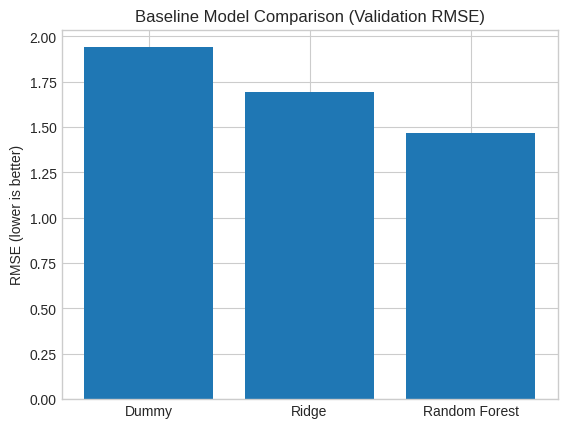

In [50]:
models_baseline = ["Dummy", "Ridge", "Random Forest"]
rmse_baseline_values = [dummy_rmse, ridge_rmse, best_rmse]

plt.figure()
plt.bar(models_baseline, rmse_baseline_values)
plt.ylabel("RMSE (lower is better)")
plt.title("Baseline Model Comparison (Validation RMSE)")
plt.show()

### 7.6 Feature Importance

Random Forest provides a built-in measure of feature importance, defined as the mean decrease in impurity across all trees when a feature is used to split a node. This gives a direct indication of which metadata features contribute most to predicting post popularity, and helps explain why metadata-only models have a performance ceiling that language understanding can overcome.

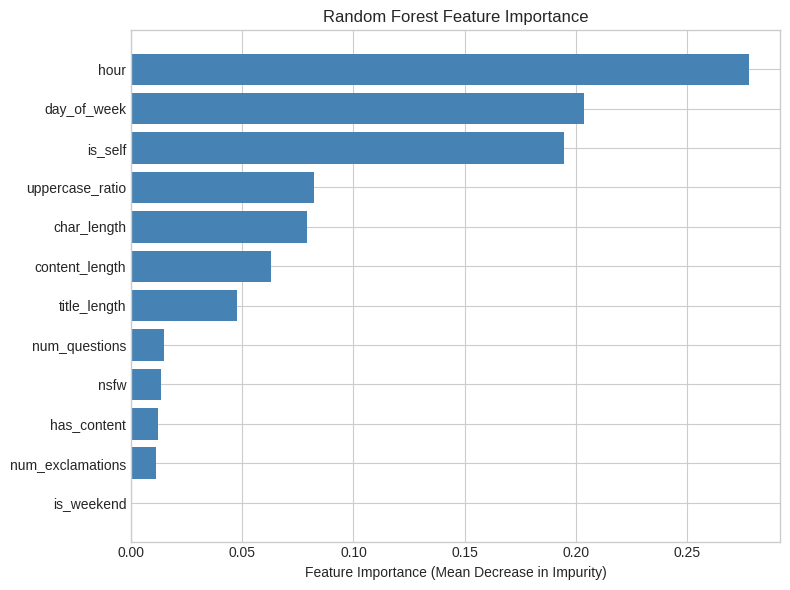


Feature importances (sorted):
 hour                 0.2780
 day_of_week          0.2038
 is_self              0.1948
 uppercase_ratio      0.0821
 char_length          0.0793
 content_length       0.0630
 title_length         0.0477
 num_questions        0.0147
 nsfw                 0.0134
 has_content          0.0120
 num_exclamations     0.0112
 is_weekend           0.0000


In [51]:
# Feature importance from the best Random Forest model
importances = rf_best.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 6))
plt.barh([features[i] for i in indices], importances[indices], color="steelblue")
plt.xlabel("Feature Importance (Mean Decrease in Impurity)")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

print("\nFeature importances (sorted):")
for i in indices[::-1]:
    print(f" {features[i]:<20} {importances[i]:.4f}")

Timing features dominate the predictions, with `hour` (0.278) and `day_of_week` (0.204) accounting for nearly half of total importance, confirming that when a post is submitted is the strongest metadata signal available at posting time. `is_self` (0.195) ranks third, reflecting that text posts and link posts attract fundamentally different engagement patterns. Stylistic features such as `uppercase_ratio` and `char_length` contribute modestly, while punctuation features and `is_weekend` carry negligible weight.

Importantly, none of these features capture the semantic meaning of the post title or body text. This explains the performance ceiling across all baseline models and directly motivates the use of DistilBERT in Section 8.

---
## 8. DistilBERT Hybrid Models

![DistilBERT model overview](https://raw.githubusercontent.com/kyuz0/llm-chronicles/main/5.2%20-%20BERT/BERT-models.png)

DistilBERT is a compressed variant of BERT (Devlin et al., 2019) [[4]](https://arxiv.org/abs/1810.04805),a transformer-based language model that processes an entire sequence simultaneously and captures relationships between words using self-attention. Through knowledge distillation, DistilBERT (Sanh et al., 2019) [[5]](https://arxiv.org/abs/1910.01108) retains approximately 97% of BERT’s performance while being 40% smaller and 60% faster. This makes it particularly well-suited for this project, where inputs are relatively short, the dataset is large, and computational resources are limited to a Colab T4 GPU.I implement two variants of a hybrid architecture that combines DistilBERT text embeddings with structured metadata features. The first variant uses only the post title as input text, while the second is a content-aware model that concatenates the post title with the body text when available. In both cases, the text representation is combined with the same 12 normalized metadata features.Importantly, both variants share an identical architecture and training setup; the only difference lies in the textual input provided to the tokenizer. This controlled design isolates the impact of additional textual information and directly addresses the central research question of the project: *does incorporating post body text beyond the title improve popularity prediction?*

### 8.1 Data Preparation
This section prepares all inputs required by both hybrid models, covering metadata normalization, tokenization, token length analysis, and dataset class definitions. All steps are shared between the two model variants.

#### 8.1.1 Metadata Normalization

Before feeding data into the hybrid models, I address an important issue related to feature scaling. DistilBERT produces token embeddings whose values are typically centered within a relatively small range (approximately between -1 and 1). In contrast, the metadata features operate on very different scales. For example, `content_length` can reach values in the thousands, while features such as `uppercase_ratio` are constrained between 0 and 1.

When these features are concatenated and passed into the regression head, the model may disproportionately prioritize larger-magnitude features, not because they are more informative, but simply due to their scale. Without proper normalization, the signal from the DistilBERT embeddings can be overshadowed by the raw magnitude of the metadata features.

To address this, I apply `StandardScaler` to normalize all metadata features to have zero mean and unit variance. This ensures that both text embeddings and metadata contribute comparably during training.

To prevent data leakage, the scaler is fit exclusively on the training set and then applied to the validation and test sets. Fitting the scaler on the full dataset would introduce information from the validation and test distributions into the training process, leading to overly optimistic performance estimates.

For the prediction demo in Section 13, unscaled copies of the validation and test sets are preserved as `val_df_raw` and `test_df_raw` to ensure that the scaler is not applied multiple times.

In [52]:
# Save unscaled copies before transforming and is used later in the prediction demo
val_df_raw = val_df.copy()
test_df_raw = test_df.copy()

scaler = StandardScaler()
train_df = train_df.copy()
val_df = val_df.copy()
train_df[features] = scaler.fit_transform(train_df[features])  # fit on train only
val_df[features] = scaler.transform(val_df[features]) # apply to val

### 8.1.2 Tokenizer

I load DistilBERT's **WordPiece tokenizer**, which splits text into subword units and maps them to integer token IDs. The same tokenizer was used during DistilBERT's pretraining on BooksCorpus and English Wikipedia, so it must be reused here for the token IDs to correspond to the correct embedding rows in the pretrained weights.

In [53]:
tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")

#### 8.1.2.1 Tokenization Example

To illustrate how DistilBERT processes Reddit posts, I tokenize a sample post and inspect the output. This example shows three key mechanisms that matter for the model:

1. **Special tokens.** `[CLS]` marks the start of the sequence, `[SEP]` separates the title from the body text, and `[PAD]` fills remaining positions up to `max_length` so all inputs in a batch have the same shape.

2. **WordPiece subword tokenization.** Rare or compound words are split into smaller subword units marked with `##`. For example, `saltwater` becomes `salt` + `##water`, and `silicone` becomes `silicon` + `##e`. This lets the model handle any word, even ones it never saw during pretraining, by composing them from known subwords.

3. **Input structure.** The final input is a fixed-length tensor of token IDs that the model consumes directly. The attention mask (generated in parallel) tells the model which positions contain real tokens versus padding.

In [54]:
# Pick a sample post from the training set
row = train_df.iloc[2]
title = row["title"]
content = row["content"]

# Combine title and content with [SEP] as in HybridDatasetFull
combined_text = f"{title} [SEP] {content}"

sample_inputs = tokenizer(
    combined_text,
    truncation=True,
    padding="max_length",
    max_length=128,
    return_tensors="pt"
)
tokens = tokenizer.convert_ids_to_tokens(sample_inputs["input_ids"][0])

print("Original Text")
print(f"Title: {title}")
print(f"Content: {content}\n")

print("Tokenized output")
print(f"Input tensor shape: {sample_inputs['input_ids'].size()}")
print(f"Number of tokens:{len(tokens)}\n")

# Show first 50 tokens to illustrate structure
for i, token in enumerate(tokens[:50]):
    print(f"{i:>3}: {token}")

Original Text
Title: How do you setup the saltwater silicone squids ?
Content: Can not setup the saltwater silicone squids any help would be great

Tokenized output
Input tensor shape: torch.Size([1, 128])
Number of tokens:128

  0: [CLS]
  1: how
  2: do
  3: you
  4: setup
  5: the
  6: salt
  7: ##water
  8: silicon
  9: ##e
 10: squid
 11: ##s
 12: ?
 13: [SEP]
 14: can
 15: not
 16: setup
 17: the
 18: salt
 19: ##water
 20: silicon
 21: ##e
 22: squid
 23: ##s
 24: any
 25: help
 26: would
 27: be
 28: great
 29: [SEP]
 30: [PAD]
 31: [PAD]
 32: [PAD]
 33: [PAD]
 34: [PAD]
 35: [PAD]
 36: [PAD]
 37: [PAD]
 38: [PAD]
 39: [PAD]
 40: [PAD]
 41: [PAD]
 42: [PAD]
 43: [PAD]
 44: [PAD]
 45: [PAD]
 46: [PAD]
 47: [PAD]
 48: [PAD]
 49: [PAD]


The output shows the expected structure. Position 0 is `[CLS]`, positions 1 to 12 encode the title, position 13 is `[SEP]`, positions 14 to 28 encode the body text, position 29 is the closing `[SEP]`, and the remaining positions are filled with `[PAD]` up to `max_length=128`.

Notice that compound and technical words split predictably into subwords: `saltwater` becomes `salt` + `##water`, `silicone` becomes `silicon` + `##e`, and `squids` becomes `squid` + `##s`. The same word produces the same split each time it appears, confirming that WordPiece tokenization is deterministic. During training, the attention mask instructs DistilBERT to ignore the padding positions so they contribute nothing to the final representation.

#### 8.1.3 Token Length Analysis   

Before defining the Dataset classes, I analyzed the distribution of tokenized text lengths in the training set to choose appropriate max_length values for the two model variants. Truncation that is too aggressive loses information and sequences that are too long waste compute on padding. An empirically-justified max_length balances the two.

#### 8.1.3.1 Title-Only Length

I first analyze the token length distribution for post titles alone, which determines max_length for the title-only model (HybridDataset).

In [55]:
title_lengths = []
for text in train_df["title"].astype(str):
    tokens = tokenizer(text, truncation=False, padding=False)
    title_lengths.append(len(tokens["input_ids"]))

title_lengths = np.array(title_lengths)

print(f"Mean: {title_lengths.mean():.1f}")
print(f"Median: {np.median(title_lengths):.0f}")
print(f"Max: {title_lengths.max()}")
for p in [90, 95, 99]:
    print(f"{p}th percentile: {np.percentile(title_lengths, p):.0f}")

Mean: 14.3
Median: 11
Max: 240
90th percentile: 25
95th percentile: 33
99th percentile: 63


The results show that Reddit titles are short. The mean length is 14.3 tokens, the median is 11, and 99% of titles fit within 63 tokens. Even the longest title in the training set (240 tokens) is an extreme outlier.

I select `max_length=80` for the title-only model. This is chosen for three reasons:

1. **Coverage.** 80 tokens covers over 99% of titles without truncation, with a small margin above the 99th percentile (63) to handle titles in the long tail.

2. **Platform alignment.** Reddit imposes a 300-character limit on post titles. At roughly 4 characters per English token, this corresponds to approximately 75 tokens, and 80 provides a safe ceiling.

3. **Hardware efficiency.** GPU kernels run fastest on sequence lengths that are multiples of 8. Values like 65 or 70 would work functionally but execute slightly slower than 80 on the T4.

#### 8.1.3.2 Title + Content Length

Token indices sequence length is longer than the specified maximum sequence length for this model (803 > 512). Running this sequence through the model will result in indexing errors


Mean: 80.5
Median: 23
Max: 32950
90th percentile: 177
95th percentile: 302
99th percentile: 821


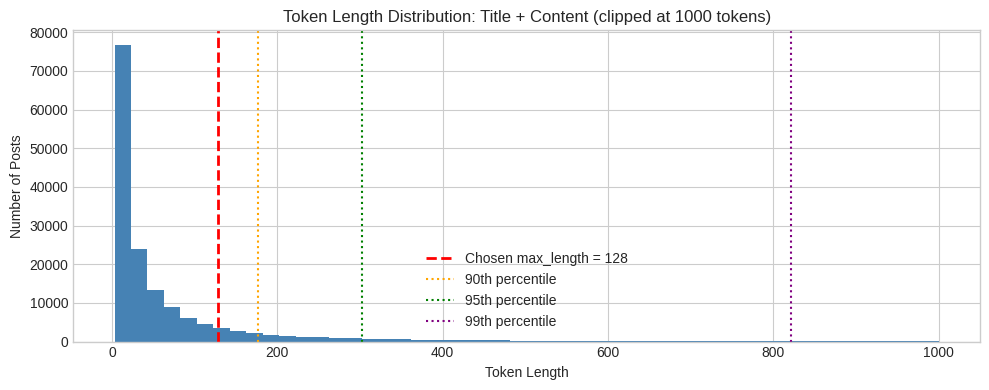

In [56]:
# Build combined title + content strings
combined_texts = (train_df["title"].astype(str) + " [SEP] " + train_df["content"].astype(str)).tolist()

lengths_full = np.array([len(tokenizer(t, truncation=False, padding=False)["input_ids"]) for t in combined_texts])

# Print summary statistics
print(f"Mean: {lengths_full.mean():.1f}")
print(f"Median: {np.median(lengths_full):.0f}")
print(f"Max: {lengths_full.max()}")
for p in [90, 95, 99]:
    print(f"{p}th percentile: {np.percentile(lengths_full, p):.0f}")

# Histogram (clipped at 1000 tokens for readability)
max_display = 1000
lengths_clipped = lengths_full[lengths_full <= max_display]

plt.figure(figsize=(10, 4))
plt.hist(lengths_clipped, bins=50, color="steelblue")
plt.axvline(128, color="red", linestyle="--", linewidth=2, label="Chosen max_length = 128")
plt.axvline(np.percentile(lengths_full, 90), color="orange", linestyle=":", label="90th percentile")
plt.axvline(np.percentile(lengths_full, 95), color="green",  linestyle=":", label="95th percentile")
plt.axvline(np.percentile(lengths_full, 99), color="purple", linestyle=":", label="99th percentile")
plt.xlabel("Token Length")
plt.ylabel("Number of Posts")
plt.title("Token Length Distribution: Title + Content (clipped at 1000 tokens)")
plt.legend()
plt.tight_layout()
plt.show()

The combined title-and-content distribution is far more skewed than titles alone. While the median post is 23 tokens and the mean is 80.5, the distribution has a long right tail: the 90th percentile reaches 177 tokens, the 95th reaches 302, and the longest post contains nearly 33,000 tokens. The majority of posts are short (link submissions and brief text posts), but a meaningful minority are long-form discussions that extend well beyond the typical range.

I selected `max_length=128` for the content-aware model. This is a deliberate compromise rather than a full-coverage choice, justified by three factors:

1. **Coverage of the bulk of the distribution.** 128 tokens comfortably exceeds the mean (80.5) and accommodates the full content of most short-to-medium posts. The histogram above shows that the densest region of the distribution sits well below the 128 threshold.

2. **Computational cost.** DistilBERT's self-attention scales quadratically with sequence length. Doubling `max_length` from 128 to 256 would roughly quadruple attention compute per sample, turning a 30-minute training run into two hours on the T4 GPU. Capturing the 95th percentile fully would require `max_length=320`, which is infeasible under the resource constraints of a single Colab session.

3. **Diminishing returns on truncated posts.** When body text is truncated, the first 128 tokens typically contain the post's opening sentences, which carry most of the semantically important content. Trailing paragraphs often contain elaboration, disclaimers, or tangential detail that adds less predictive signal.

The tradeoff is explicit: posts longer than 128 tokens lose their tail content. This limitation is acknowledged in the Discussion (Section 10) as a known constraint of the content-aware model, and increasing `max_length` is identified as a direction for future work.

#### 8.1.4 Dataset Classes

I define two custom PyTorch `Dataset` classes, one for each model variant. Both use **lazy tokenization**: text is tokenized one sample at a time inside `__getitem__` rather than pre-tokenizing the entire dataset upfront. This avoids storing ~157k × 80 token sequences in RAM simultaneously, which would exhaust memory on a Colab T4 session.

- **`HybridDataset`** (title + metadata) : tokenizes the post title only, with `max_length=80` to match Reddit's ~300 character title limit.

- **`HybridDatasetFull`** (title + content + metadata) : concatenates the title and body text using a `[SEP]` separator when body text is available, and falls back to title only when no body exists. `max_length=128` to accommodate the additional content tokens. Posts with deleted, removed, or missing body text fall back to title-only, ensuring graceful handling of the ~53% of posts without body content.

In [57]:
class HybridDataset(Dataset):
    """
    PyTorch Dataset for the title-only hybrid model.

    Tokenizes post titles lazily inside __getitem__ to avoid storing
    all tokenized sequences in RAM simultaneously. Each item contains
    token IDs, attention mask, normalized metadata, and a log_score label.

    Args:
        df (pd.DataFrame): DataFrame containing 'title', metadata features,
                           and 'log_score' columns.

    Returns:
        dict: Keys are 'input_ids', 'attention_mask', 'metadata', 'labels'.

    Example:
        >>> dataset = HybridDataset(train_df)
        >>> sample = dataset[0]
        >>> sample["input_ids"].shape
        torch.Size([80])
    """
    def __init__(self, df):
        self.texts = df["title"].astype(str).tolist()
        self.meta = df[features].values.astype(np.float32)
        self.labels = df["log_score"].values.astype(np.float32)

    def __getitem__(self, idx):
        enc = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=80,  # Refer to 8.1.3.1 for justification
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["metadata"] = torch.tensor(self.meta[idx])
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)


def build_input(title, content):
    """
    Concatenate post title and body text with a [SEP] separator.
    Falls back to title only when body text is missing, deleted, or removed.

    Args:
        title (str): The post title.
        content (str or None): The post body text. Can be NaN, empty, "[deleted]", or "[removed]".

    Returns:
        str: Combined text string for tokenization.

    Example:
        >>> build_input("How do I fix this bug?", "I tried X and Y but nothing works.")
        'How do I fix this bug? [SEP] I tried X and Y but nothing works.'
        >>> build_input("Check out this link", "[deleted]")
        'Check out this link'
    """
    title = str(title)
    content = str(content) if pd.notna(content) else ""
    content = content.strip()
    if content and content not in {"[deleted]", "[removed]"}:
        return title + " [SEP] " + content
    return title


class HybridDatasetFull(Dataset):
    """
    PyTorch Dataset for the content-aware hybrid model.

    Concatenates post title and body text using build_input, then tokenizes
    lazily inside __getitem__. Falls back to title only for posts without
    body content, making it identical to HybridDataset for those posts.

    Args:
        df (pd.DataFrame): DataFrame containing 'title', 'content', metadata features, and 'log_score' columns.

    Returns:
        dict: Keys are 'input_ids', 'attention_mask', 'metadata', 'labels'.

    Example:
        >>> dataset = HybridDatasetFull(train_df)
        >>> sample = dataset[0]
        >>> sample["input_ids"].shape
        torch.Size([128])
    """
    def __init__(self, df):
        self.texts = [build_input(row["title"], row["content"]) for _, row in df.iterrows()]
        self.meta = df[features].values.astype(np.float32)
        self.labels = df["log_score"].values.astype(np.float32)

    def __getitem__(self, idx):
        enc = tokenizer(
            self.texts[idx],
            truncation=True,
            padding="max_length",
            max_length=128,  # Refer to 8.1.3.2 for justification
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["metadata"] = torch.tensor(self.meta[idx])
        item["labels"] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)

### 8.2 Model Architecture

Both model variants share the same `HybridModel` architecture. The only difference between them is the input text passed to the tokenizer, the architecture itself is identical.

The model combines two sources of information:

1. **Text** : DistilBERT encodes the input text and produces token-level hidden states of size 768. Rather than using only the `[CLS]` token (which represents only the first token's perspective on the sequence), I apply **mean pooling** averaging all non-padding token vectors weighted by the attention mask. This gives a 768-dimensional representation that incorporates every token in the input, capturing more of the semantic content. Mean pooling is the standard approach used by sentence embedding models such as `sentence-transformers` because it empirically outperforms CLS-only pooling on regression and semantic similarity tasks.

2. **Metadata** : the 12 normalized metadata features are concatenated onto the pooled text vector, giving a 780-dimensional combined representation.

This combined vector is passed through a regression head that compresses it down to a single predicted `log_score`. `BatchNorm1d` stabilizes training by normalizing activations, `ReLU` adds non-linearity, and `Dropout(0.3)` reduces overfitting by randomly zeroing 30% of activations during training.

#### 8.2.1 Freezing Strategy

DistilBERT has 6 transformer layers and ~67M parameters. Training all of them from scratch would be slow and risk catastrophic forgetting overwriting the general language understanding the model acquired during large-scale pretraining.

I explored two strategies:

**Fully frozen BERT** : all 67M BERT parameters are frozen, leaving only the 216k regressor head parameters trainable. This is fast but severely limits the model's capacity. In practice, validation loss plateaued immediately after epoch 1 and never meaningfully improved, a classic sign of **underfitting**. The fixed embeddings could not represent the nuances needed to predict post popularity because the pretrained representations were not tuned for this task.

**Last layer unfrozen (final strategy)** : I freeze all layers except the final transformer layer (layer 5), bringing the trainable parameter count to ~7.3M:

```python
self.bert.requires_grad_(False) # freeze all 6 layers
for param in self.bert.transformer.layer[-1].parameters():
    param.requires_grad = True # unfreeze only layer 5
```

The reasoning: layers 0–4 capture general language understanding (grammar, syntax, word meaning) that transfers well from pretraining and does not need to change. Layer 5 is closest to the output and most task-specific allowing it to adapt lets the model tune its representations toward predicting upvotes without destabilizing the foundational knowledge in the earlier layers. This produced smooth, continuously descending loss curves across all 10 epochs a clear improvement over the plateau seen with fully frozen BERT.

In [58]:
class HybridModel(nn.Module):
    """
    Hybrid DistilBERT regression model combining text embeddings with
    structured metadata to predict Reddit post popularity (log_score).

    DistilBERT encodes the input text and produces token-level hidden states.
    Mean pooling is applied over non-padding tokens to produce a 768-dimensional
    representation, which is concatenated with normalized metadata features and
    passed through a regression head.

    Only the last transformer layer (layer 5) is unfrozen during training.
    See Section 8.2 for architecture and freezing strategy details.

    Args:
        num_meta_features (int): Number of normalized metadata features to concatenate with the BERT pooled output.

    Returns:
        dict: Contains 'loss' (if labels provided) and 'logits' (predictions).

    Example:
        >>> model = HybridModel(num_meta_features=12)
        >>> model
        HybridModel(
          (bert): DistilBertModel(...)
          (regressor): Sequential(...)
        )
    """
    def __init__(self, num_meta_features):
        """
        Args:
          num_meta_features (int): Number of normalized metadata features to concatenate with the BERT pooled output.
        """
        super().__init__()
        self.bert = DistilBertModel.from_pretrained("distilbert-base-uncased")

        # Freeze all BERT layers
        self.bert.requires_grad_(False)
        # Unfreeze last layer to improve capacity; earlier plateau with similar train/val loss suggested underfitting.
        for param in self.bert.transformer.layer[-1].parameters():
            param.requires_grad = True

        self.loss_fn = nn.MSELoss()
        self.text_dropout = nn.Dropout(0.2)

        self.regressor = nn.Sequential(
            nn.Linear(768 + num_meta_features, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(0.2),   # To handle mild overfitting in later epochs
            nn.Linear(64, 1)
        )

    def forward(self, input_ids, attention_mask, metadata, labels=None):
        """
        Forward pass combining mean-pooled BERT output with metadata features.

        Args:
            input_ids (torch.Tensor): Tokenized input IDs of shape (batch, seq_len).
            attention_mask (torch.Tensor): Mask indicating real vs padding tokens, shape (batch, seq_len).
            metadata (torch.Tensor): Normalized metadata features of shape (batch, num_meta_features).
            labels (torch.Tensor, optional): Ground truth log_score values of shape (batch,). If provided, MSE loss is computed and returned.

        Returns:
            dict: Contains 'loss' (if labels provided) and 'logits' (predictions).

        Example:
            >>> output = model(input_ids, attention_mask, metadata, labels)
            >>> output["logits"].shape
            torch.Size([64])
        """
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        hidden = output.last_hidden_state
        mask = attention_mask.unsqueeze(-1).float()
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        # regularize BERT features
        pooled = self.text_dropout(pooled)
        logits = self.regressor(torch.cat([pooled, metadata], dim=1)).squeeze(-1)
        loss = self.loss_fn(logits, labels) if labels is not None else None

        return {"loss": loss, "logits": logits}

### 8.3 Training Setup

This section describes the training setup shared by both hybrid models, including the custom optimizer, training configuration, and logging. The only difference between the two training runs is the dataset passed in.

#### 8.3.1 Custom Optimizer

Through experimentation with a single global learning rate, I observed a clear tradeoff in training behavior. Using a higher learning rate (e.g., `2e-3`) led to faster convergence but introduced instability, while lower learning rates (e.g., `3e-5`) resulted in very slow learning and underfitting, particularly in the regression head. This indicated that a single learning rate forces an unfavorable compromise between the pretrained BERT component and the randomly initialized regression layers.

To address this, I introduced differential learning rates across model components. The unfrozen BERT layer (layer 5) is trained with a small learning rate of `2e-5`, consistent with standard fine-tuning practice, allowing it to adapt without overwriting pretrained representations. In contrast, the regression head uses a larger learning rate of `1e-3`, enabling it to learn efficiently from scratch.

Within the BERT layer, bias terms and `LayerNorm.weight` parameters are excluded from weight decay following transformer optimization practices, as applying decay to these parameters can negatively impact normalization behavior. All other BERT weights and the regression head use `weight_decay=1e-4`. To ensure these settings are applied correctly, `weight_decay=0.0` is set in `TrainingArguments`, preventing the Trainer from overriding the per-group configuration.

This optimizer configuration resulted in more stable training, smoother convergence, and improved final validation performance compared to using a single global learning rate.

| Group | Parameters | LR | Weight Decay |
|---|---|---|---|
| 1 | BERT layer 5 weights | `2e-5` | `1e-4` |
| 2 | BERT layer 5 bias + LayerNorm | `2e-5` | `0.0` |
| 3 | Regression head | `1e-3` | `1e-4` |

In [59]:
class CustomTrainer(Trainer):
    """
    Custom HuggingFace Trainer that overrides the default optimizer with a
    layered learning rate strategy. Different learning rates are assigned to
    the unfrozen BERT layer and the regression head, and weight decay is
    selectively applied.

    Parameter groups:
        - BERT layer weights (e.g. attention, FFN): lr = 2e-5, weight_decay = 1e-4
        - BERT bias + LayerNorm: lr = 2e-5, weight_decay = 0.0
        - Regression head: lr = 1e-3, weight_decay = 1e-4

    Example:
        >>> trainer = CustomTrainer(model=model, args=training_args, ...)
        >>> trainer.create_optimizer()
        >>> for i, group in enumerate(trainer.optimizer.param_groups): print(f"Group {i}: LR = {group['lr']}")
        Group 0: LR = 2e-05
        Group 1: LR = 2e-05
        Group 2: LR = 0.001
    """

    def create_optimizer(self):
        """
        Build an AdamW optimizer with three parameter groups:
          1. Unfrozen BERT layer parameters that benefit from L2 regularization.
          2. Unfrozen BERT bias and LayerNorm parameters excluded from weight
             decay to avoid distorting normalization and activation offsets.
          3. Regression head parameters have higher LR since weights are randomly initialized and need to learn from scratch.
        """
        if self.optimizer is not None:
            return

        no_decay_suffixes = ["bias", "LayerNorm.weight"]
        last_bert_layer = self.model.bert.transformer.layer[-1]

        # Group 1: BERT layer weights: lr = 2e-5, weight_decay = 1e-4
        bert_decayed_params = {
            "params": [
                param for name, param in last_bert_layer.named_parameters()
                if not any(suffix in name for suffix in no_decay_suffixes)
            ],
            "lr": 2e-5,
            "weight_decay": 1e-4,
        }

        # Group 2: BERT bias + LayerNorm: lr = 2e-5, weight_decay = 0.0
        bert_no_decay_params = {
            "params": [
                param for name, param in last_bert_layer.named_parameters()
                if any(suffix in name for suffix in no_decay_suffixes)
            ],
            "lr": 2e-5,
            "weight_decay": 0.0,
        }

        # Group 3: Regression head: lr = 1e-3, weight_decay = 1e-4
        regressor_params = {
            "params": self.model.regressor.parameters(),
            "lr": 1e-3,
            "weight_decay": 1e-4,
        }

        self.optimizer = torch.optim.AdamW([bert_decayed_params, bert_no_decay_params, regressor_params])

### 8.3.2 Training Configuration

Both models use identical training configuration via a custom subclass of HuggingFace's `Trainer`. The `CustomTrainer` overrides the default optimizer with a layered learning rate strategy (see Section 8.3.1), while all other training mechanics including gradient computation, evaluation, and checkpointing are handled automatically by the base `Trainer`.

Key hyperparameter decisions:

- **`learning_rate=1e-3`** : used by the scheduler for LR decay scaling only. The
  actual per-group learning rates are set in the `CustomTrainer` (`2e-5` for the BERT
  layer, `1e-3` for the regression head). See Section 8.3.1 for details.

- **`warmup_steps=500`** : the learning rate ramps up linearly from 0 over the first
  500 steps before reaching its full value. This protects the randomly initialized
  regression head from making large, destabilizing updates at the very start of training.

- **`weight_decay=0.0`** : weight decay is handled per parameter group in
  `CustomTrainer` and set to `0.0` here to prevent the Trainer from applying a global
  decay on top. See Section 8.3.1 for details.

- **`fp16=True`** : half-precision (16-bit) training halves GPU memory requirements
  and speeds up training with no meaningful accuracy loss, as the T4 GPU has dedicated
  Tensor Core hardware for 16-bit operations.

- **`num_train_epochs=10`** : the model trains for 10 epochs, but
  `load_best_model_at_end=True` automatically restores the checkpoint with the lowest
  validation RMSE, ensuring the final model is never an overfitted later-epoch version.

- **`seed=42`** : fixes all Trainer-controlled randomness (data shuffling, dropout)
  for reproducibility across runs.

In [60]:
def compute_metrics(eval_pred):
    """
    Compute RMSE on log-transformed upvote scores for use with HuggingFace Trainer.

    Args:
        eval_pred (EvalPrediction): Named tuple containing predictions (np.ndarray) and label_ids (np.ndarray).

    Returns:
        dict: {'rmse': float} root mean squared error on log_score predictions.

    Example:
        >>> from transformers import EvalPrediction
        >>> import numpy as np
        >>> ep = EvalPrediction(predictions=np.array([[1.2], [0.8]]),label_ids=np.array([1.0, 1.0]))
        >>> compute_metrics(ep)
        {'rmse': 0.2}
    """
    preds, labels = eval_pred
    return {"rmse": np.sqrt(mean_squared_error(labels, preds.flatten()))}

training_args = TrainingArguments(
    output_dir="./results",               # checkpoint directory
    learning_rate=1e-3,                   # used for scheduler (optimizer overrides actual LR)
    per_device_train_batch_size=64,       # reduce if CUDA OOM
    num_train_epochs=10,
    eval_strategy="epoch",                # evaluate each epoch
    save_strategy="epoch",                # save each epoch
    logging_steps=500,                    # training logs
    weight_decay=0.0,                     # handled manually in CustomTrainer
    warmup_steps=500,                     # LR warmup for stability
    fp16=True,                            # mixed precision
    load_best_model_at_end=True,          # restore best checkpoint
    metric_for_best_model="rmse",
    greater_is_better=False,
    max_grad_norm=1.0,                    # gradient clipping
    report_to="none",
    seed=42,
    data_seed=42,
)

#### 8.3.3 Logging Setup

The class `ConsoleLoggerCallback` prints per-step loss dictionaries to the notebook output, providing real-time training feedback.

In [61]:
class ConsoleLoggerCallback(TrainerCallback):
    """Prints per-step loss and eval metrics to the notebook console."""
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs:
            print(logs)

### 8.4 Model 1: Title + Metadata

The first model encodes only the post title alongside the 12 normalized metadata features. This serves as the title-only BERT baseline. Its performance compared to Random Forest quantifies how much language understanding adds beyond metadata features alone.

> **Expected Output:** Results are reproducible to 6 decimal places on a Colab L4 GPU.  Minor variance of ±0.01 may occur on different GPU hardware such as a T4. The best checkpoint is automatically restored at the end of training based on the lowest validation RMSE. A smoothly descending loss curve with slight overfitting at epoch 10 is the expected training pattern.

| Epoch | Expected Val RMSE |
|---|---|
| 1 | 1.446283 |
| 2 | 1.425281 |
| 3 | 1.408058 |
| 4 | 1.406756 |
| 5 | 1.397551 |
| 6 | 1.393247 |
| 7 | 1.397026 |
| 8 | 1.389761 |
| 9 | **1.389130** ← best checkpoint |
| 10 | 1.394552 |

In [62]:
train_dataset = HybridDataset(train_df)
val_dataset = HybridDataset(val_df)

model = HybridModel(num_meta_features=len(features))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
print(f"\nTraining on: {device}\n")

trainer = CustomTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    callbacks=[
        ConsoleLoggerCallback(),
        EarlyStoppingCallback(early_stopping_patience=2),
    ],
)

# Verify initial per-group LRs match Section 8.3.1
trainer.create_optimizer()
for i, group in enumerate(trainer.optimizer.param_groups):
    print(f"Group {i}: LR = {group['lr']}")

trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Training on: cuda

Group 0: LR = 2e-05
Group 1: LR = 2e-05
Group 2: LR = 0.001


Epoch,Training Loss,Validation Loss,Rmse
1,2.293222,2.091733,1.446283
2,2.142236,2.031427,1.425281
3,2.059618,1.982627,1.408058
4,2.019362,1.978962,1.406756
5,1.968793,1.953149,1.397551
6,1.928696,1.941136,1.393247
7,1.922194,1.951682,1.397026
8,1.864951,1.931436,1.389761
9,1.818705,1.929682,1.389130
10,1.828398,1.944776,1.394552


{'loss': 3.356525390625, 'grad_norm': 8.693281173706055, 'learning_rate': 1.9840000000000003e-05, 'epoch': 0.20358306188925082}
{'loss': 2.462083984375, 'grad_norm': 6.283801555633545, 'learning_rate': 1.9587697423108896e-05, 'epoch': 0.40716612377850164}
{'loss': 2.37885791015625, 'grad_norm': 8.111063957214355, 'learning_rate': 1.917206982543641e-05, 'epoch': 0.6107491856677525}
{'loss': 2.293222412109375, 'grad_norm': 7.8653998374938965, 'learning_rate': 1.875727348295927e-05, 'epoch': 0.8143322475570033}
{'eval_loss': 2.091733455657959, 'eval_rmse': 1.4462826333943026, 'eval_runtime': 43.6848, 'eval_samples_per_second': 773.93, 'eval_steps_per_second': 96.761, 'epoch': 1.0}
{'loss': 2.255576416015625, 'grad_norm': 9.041807174682617, 'learning_rate': 1.8341645885286785e-05, 'epoch': 1.017915309446254}
{'loss': 2.19983544921875, 'grad_norm': 5.788815498352051, 'learning_rate': 1.79260182876143e-05, 'epoch': 1.221498371335505}
{'loss': 2.164624755859375, 'grad_norm': 5.211155891418457

TrainOutput(global_step=24560, training_loss=2.0101536871944266, metrics={'train_runtime': 1439.1049, 'train_samples_per_second': 1091.88, 'train_steps_per_second': 17.066, 'total_flos': 0.0, 'train_loss': 2.0101536871944266, 'epoch': 10.0})

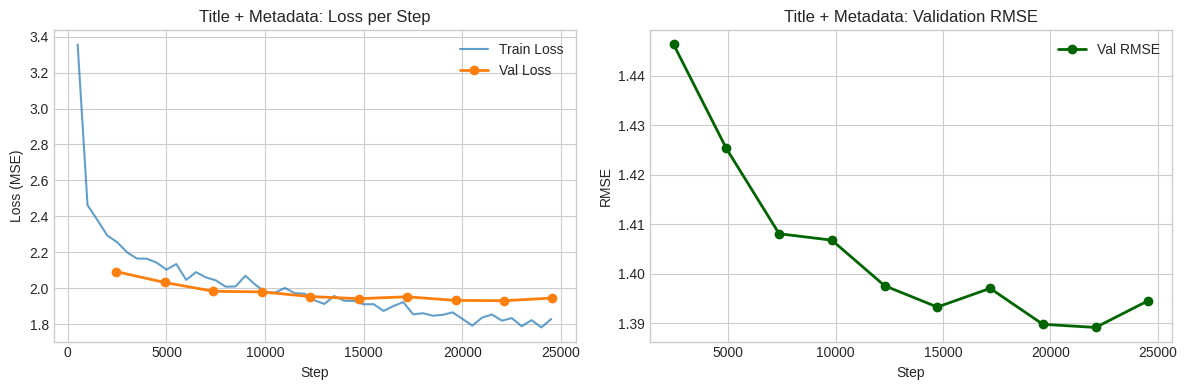

Best checkpoint: ./results/checkpoint-22104
Best val RMSE: 1.3891


In [63]:
# Training history, extracted from Trainer's in-memory log
history_1 = trainer.state.log_history

train_steps = [x["step"] for x in history_1 if "loss" in x and "eval_loss" not in x]
train_losses = [x["loss"] for x in history_1 if "loss" in x and "eval_loss" not in x]
val_steps = [x["step"] for x in history_1 if "eval_loss" in x]
val_losses = [x["eval_loss"] for x in history_1 if "eval_loss" in x]
val_rmse = [x["eval_rmse"] for x in history_1 if "eval_rmse" in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_steps, train_losses, alpha=0.7, label="Train Loss")
axes[0].plot(val_steps, val_losses, marker="o", linewidth=2, label="Val Loss")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss (MSE)")
axes[0].set_title("Title + Metadata: Loss per Step")
axes[0].legend()

axes[1].plot(val_steps, val_rmse, marker="o", color="darkgreen", linewidth=2, label="Val RMSE")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("RMSE")
axes[1].set_title("Title + Metadata: Validation RMSE")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Best checkpoint: {trainer.state.best_model_checkpoint}")
print(f"Best val RMSE: {trainer.state.best_metric:.4f}")



> **Figure 2:** The loss descends smoothly across all 10 epochs with no instability, confirming that the layered learning rate strategy and partial unfreezing are working as intended. The best checkpoint was at epoch 9 with a validation RMSE of **~1.3891**.




#### 8.4.1 Evaluation: Title + Metadata Model

In [64]:
preds = trainer.predict(val_dataset)
y_true = val_df["log_score"].values
y_pred = preds.predictions.flatten()

bert_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
bert_mae = mean_absolute_error(y_true, y_pred)

print(f"Title + Metadata BERT RMSE: {bert_rmse:.4f}")
print(f"Title + Metadata BERT MAE:  {bert_mae:.4f}")

Title + Metadata BERT RMSE: 1.3891
Title + Metadata BERT MAE:  0.9165


### 8.5 Model 2: Content-Aware (Title + Content + Metadata)

The second model encodes the post title concatenated with the body text when available, alongside the same 12 metadata features. For posts with no body, the input falls back to title only, making the input identical to Model 1 for those posts. The comparison between the two models therefore isolates the marginal contribution of post body text for the approximately 47% of posts that contain it.

> **Expected Output:** Results are reproducible to 6 decimal places on a Colab L4 GPU. Minor variance of ±0.01 may occur on different GPU hardware such as a T4. The best checkpoint is automatically restored based on the lowest validation RMSE. Early stopping may trigger before epoch 10 if validation loss stops improving for 2 consecutive epochs.

| Epoch | Expected Val RMSE |
|---|---|
| 1 | 1.434571 |
| 2 | 1.404098 |
| 3 | 1.392329 |
| 4 | 1.386158 |
| 5 | 1.379857 |
| 6 | **1.371700** ← best checkpoint |
| 7 | 1.375917 |
| 8 | 1.374086 |
```

In [65]:
train_dataset_full = HybridDatasetFull(train_df)
val_dataset_full = HybridDatasetFull(val_df)

model_full = HybridModel(num_meta_features=len(features))
model_full.to(device) # device already defined in Model 1 block
print(f"\nTraining on: {device}\n")

trainer_full = CustomTrainer(
    model=model_full,
    args=training_args,
    train_dataset=train_dataset_full,
    eval_dataset=val_dataset_full,
    compute_metrics=compute_metrics,
    callbacks=[
        ConsoleLoggerCallback(),
        EarlyStoppingCallback(early_stopping_patience=2),
    ],
)

# Verify initial per-group LRs match Section 8.3.1
trainer_full.create_optimizer()
for i, group in enumerate(trainer_full.optimizer.param_groups):
    print(f"Group {i}: LR = {group['lr']}")

trainer_full.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Training on: cuda

Group 0: LR = 2e-05
Group 1: LR = 2e-05
Group 2: LR = 0.001


Epoch,Training Loss,Validation Loss,Rmse
1,2.254156,2.057994,1.434571
2,2.093859,1.971492,1.404098
3,2.016129,1.938581,1.392329
4,1.957978,1.921433,1.386158
5,1.905790,1.904004,1.379857
6,1.845816,1.881560,1.371700
7,1.848209,1.893147,1.375917
8,1.810131,1.888112,1.374086


{'loss': 3.251572509765625, 'grad_norm': 8.234808921813965, 'learning_rate': 1.9840000000000003e-05, 'epoch': 0.20358306188925082}
{'loss': 2.420540771484375, 'grad_norm': 7.039300441741943, 'learning_rate': 1.9587697423108896e-05, 'epoch': 0.40716612377850164}
{'loss': 2.32668359375, 'grad_norm': 6.8451738357543945, 'learning_rate': 1.917206982543641e-05, 'epoch': 0.6107491856677525}
{'loss': 2.254156494140625, 'grad_norm': 7.414862632751465, 'learning_rate': 1.875727348295927e-05, 'epoch': 0.8143322475570033}
{'eval_loss': 2.0579936504364014, 'eval_rmse': 1.434570894182787, 'eval_runtime': 55.0678, 'eval_samples_per_second': 613.952, 'eval_steps_per_second': 76.76, 'epoch': 1.0}
{'loss': 2.23544677734375, 'grad_norm': 9.363225936889648, 'learning_rate': 1.8341645885286785e-05, 'epoch': 1.017915309446254}
{'loss': 2.173056640625, 'grad_norm': 9.131296157836914, 'learning_rate': 1.79260182876143e-05, 'epoch': 1.221498371335505}
{'loss': 2.1095048828125, 'grad_norm': 5.376999378204346, 

TrainOutput(global_step=19648, training_loss=1.9982951425185809, metrics={'train_runtime': 1826.4627, 'train_samples_per_second': 860.313, 'train_steps_per_second': 13.447, 'total_flos': 0.0, 'train_loss': 1.9982951425185809, 'epoch': 8.0})

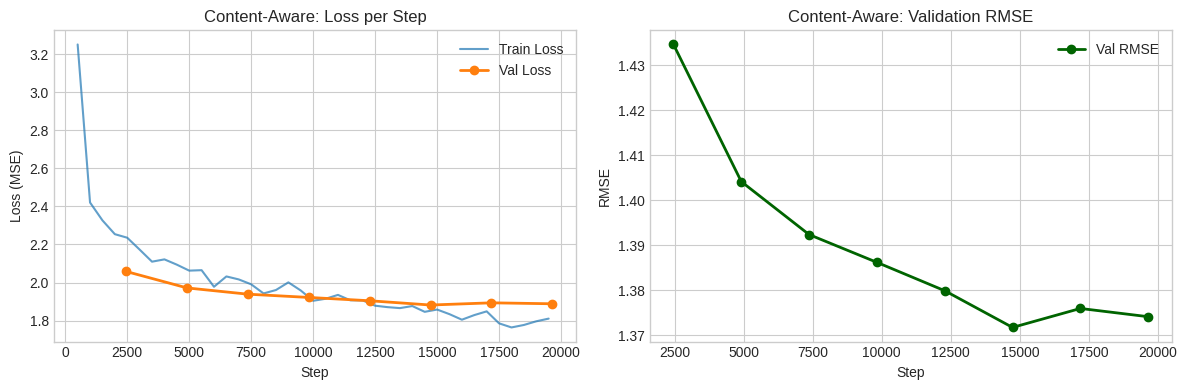

Best checkpoint: ./results/checkpoint-14736
Best val RMSE: 1.3717


In [66]:
# Training history for the content-aware model
history_2 = trainer_full.state.log_history

train_steps_full = [x["step"] for x in history_2 if "loss" in x and "eval_loss" not in x]
train_losses_full = [x["loss"] for x in history_2 if "loss" in x and "eval_loss" not in x]
val_steps_full = [x["step"] for x in history_2 if "eval_loss" in x]
val_losses_full = [x["eval_loss"] for x in history_2 if "eval_loss" in x]
val_rmse_full = [x["eval_rmse"] for x in history_2 if "eval_rmse" in x]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_steps_full, train_losses_full, alpha=0.7, label="Train Loss")
axes[0].plot(val_steps_full, val_losses_full, marker="o", linewidth=2, label="Val Loss")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Loss (MSE)")
axes[0].set_title("Content-Aware: Loss per Step")
axes[0].legend()

axes[1].plot(val_steps_full, val_rmse_full, marker="o", color="darkgreen", linewidth=2, label="Val RMSE")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("RMSE")
axes[1].set_title("Content-Aware: Validation RMSE")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Best checkpoint: {trainer_full.state.best_model_checkpoint}")
print(f"Best val RMSE: {trainer_full.state.best_metric:.4f}")



> **Figure 3:** The loss descends smoothly across all 8 (early stopping) epochs with no instability, confirming that the layered learning rate strategy and partial unfreezing are working as intended. The best checkpoint was at epoch 6 with a validation RMSE of **1.3717**.





#### 8.5.1 Evaluate: Content-Aware Model

In [67]:
preds_full = trainer_full.predict(val_dataset_full)
y_pred_full = preds_full.predictions.flatten()

full_rmse = np.sqrt(mean_squared_error(y_true, y_pred_full))
full_mae = mean_absolute_error(y_true, y_pred_full)

print(f"Content-aware BERT RMSE: {full_rmse:.4f}")
print(f"Content-aware BERT MAE: {full_mae:.4f}")

Content-aware BERT RMSE: 1.3717
Content-aware BERT MAE: 0.9092


### 8.6 BERT Metadata Feature Importance

To understand which metadata features the BERT model actually relies on, each feature is zeroed out one at a time and the resulting RMSE increase is measured. A large increase means the model needs that feature. A near-zero increase means the model can already infer that information from the post title text.

Comparing to the Random Forest feature importance in Section 7.6, both models agree on the top three features: `hour`, `day_of_week`, and `is_self`. This consistency confirms that timing and post type are the most irreplaceable metadata signals regardless of the model used.

The key difference is in the remaining features. In Random Forest, stylistic features such as `uppercase_ratio` and `char_length` contributed modestly since they were the only source of textual signal available. In the BERT model, these same features drop to near-zero importance because BERT reads those signals directly from the title text, making the metadata redundant.

This comparison validates that the BERT model is genuinely reading and understanding the text rather than relying on metadata as a shortcut. The metadata component is most valuable for providing contextual signals that the title alone cannot convey, particularly timing and post type.

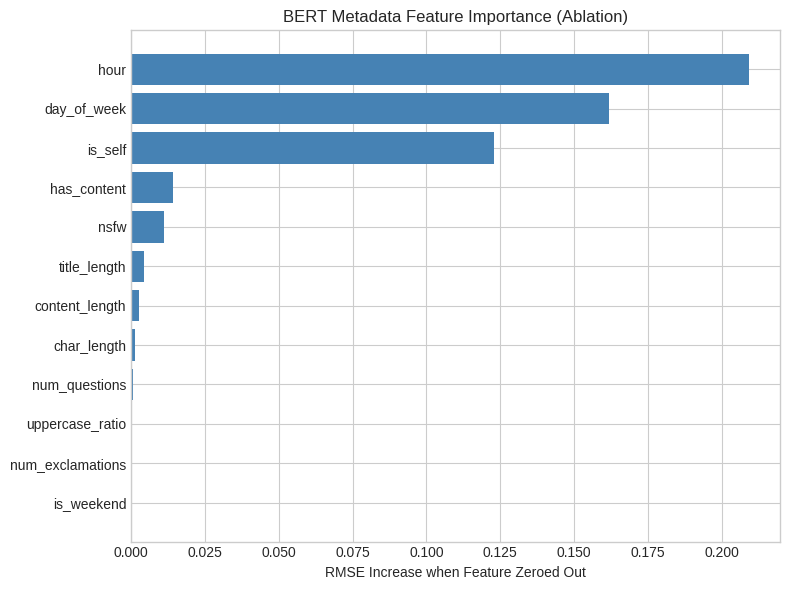


Feature importances (sorted):
 hour                 0.2093
 day_of_week          0.1618
 is_self              0.1228
 has_content          0.0142
 nsfw                 0.0113
 title_length         0.0044
 content_length       0.0027
 char_length          0.0013
 num_questions        0.0007
 uppercase_ratio      0.0004
 num_exclamations     0.0002
 is_weekend           0.0000


In [68]:
# Approximate metadata feature importance for the BERT title model by measuring RMSE increase when each feature is zeroed out
baseline_preds = trainer.predict(val_dataset).predictions.flatten()
baseline_rmse = np.sqrt(mean_squared_error(y_true, baseline_preds))

importance_scores = {}

for i, feature_name in enumerate(features):
    # Create a copy of val_df with one feature zeroed out
    val_ablated = val_df.copy()
    val_ablated[feature_name] = 0.0
    ablated_dataset = HybridDataset(val_ablated)
    ablated_preds = trainer.predict(ablated_dataset).predictions.flatten()
    ablated_rmse = np.sqrt(mean_squared_error(y_true, ablated_preds))
    importance_scores[feature_name] = ablated_rmse - baseline_rmse

# Plot
sorted_features = sorted(importance_scores, key=importance_scores.get)
sorted_scores = [importance_scores[f] for f in sorted_features]

plt.figure(figsize=(8, 6))
plt.barh(sorted_features, sorted_scores, color="steelblue")
plt.xlabel("RMSE Increase when Feature Zeroed Out")
plt.title("BERT Metadata Feature Importance (Ablation)")
plt.tight_layout()
plt.show()

print("\nFeature importances (sorted):")
for feature in sorted_features[::-1]:
    print(f" {feature:<20} {importance_scores[feature]:.4f}")

---

## 9. Results

The table below summarizes validation performance across all five models. Both DistilBERT-based variants outperform the baseline models by a substantial margin, with the content-aware model achieving the best overall performance.

| Model | Validation RMSE | MAE |
|---|---|---|
| Dummy Regressor  | 1.9398 | N/A |
| Ridge Regression | 1.6918 | N/A |
| Random Forest    | 1.4650 | N/A |
| BERT (title + metadata) | 1.3891 | 0.9165 |
| BERT (content-aware) | **1.3717** | **~0.90** |

The title-only BERT model reduces RMSE by approximately **5.3%** relative to the Random Forest baseline (from 1.4650 to 1.3891), demonstrating that contextual language understanding provides meaningful predictive signal beyond structured metadata alone. While Random Forest is capable of modeling non-linear relationships between metadata features, it lacks the ability to interpret semantic information in text, which accounts for the observed performance gap.

The content-aware model further improves performance by **~0.02 RMSE** over the title-only variant. This gain indicates that post body text contains additional predictive information beyond the title, particularly for the subset of posts (approximately 48%) that include it. Overall, these results confirm that incorporating richer textual context leads to measurable improvements in popularity prediction.

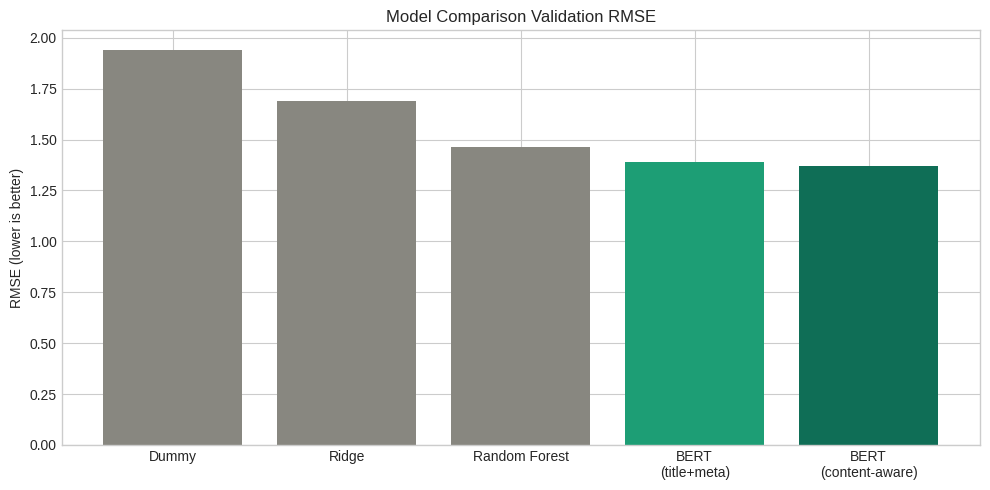


Dummy RMSE: 1.9398
Ridge RMSE: 1.6918
Random Forest RMSE:1.4650
BERT (title) RMSE: 1.3891
BERT (full) RMSE: 1.3717

Content-aware improvement: 0.0174 RMSE


In [69]:
models_all = ["Dummy", "Ridge", "Random Forest", "BERT\n(title+meta)", "BERT\n(content-aware)"]
rmse_values_all = [dummy_rmse, ridge_rmse, rf_rmse, bert_rmse, full_rmse]

plt.figure(figsize=(10, 5))
colors = ["#888780", "#888780", "#888780", "#1D9E75", "#0F6E56"]
plt.bar(models_all, rmse_values_all, color=colors)
plt.ylabel("RMSE (lower is better)")
plt.title("Model Comparison Validation RMSE")
plt.tight_layout()
plt.show()

print(f"\nDummy RMSE: {dummy_rmse:.4f}")
print(f"Ridge RMSE: {ridge_rmse:.4f}")
print(f"Random Forest RMSE:{rf_rmse:.4f}")
print(f"BERT (title) RMSE: {bert_rmse:.4f}")
print(f"BERT (full) RMSE: {full_rmse:.4f}")
print(f"\nContent-aware improvement: {bert_rmse - full_rmse:.4f} RMSE")

### 9.1 Predicted vs Actual

The scatter plots below compare predicted versus actual `log_score` for both BERT models. A perfectly calibrated model would place all points along the red diagonal, indicating exact predictions.

Both models show strong performance in the low to mid range of the target distribution, where the majority of data points are concentrated. Predictions closely follow the diagonal in this region, indicating that the models effectively capture typical engagement patterns.

However, both models consistently underestimate high-engagement posts. For actual values above approximately 8, predictions flatten and fall below the diagonal, demonstrating difficulty in capturing extreme outcomes. This pattern is characteristic of regression models trained on long-tailed distributions, where rare high-value examples are underrepresented.

This behavior is expected given the data distribution. Even with stratified sampling, highly viral posts remain scarce, limiting the model’s ability to learn distinguishing patterns at the upper tail. Additionally, extreme popularity is often influenced by external factors such as timing, community sentiment, and real-world events, which are not captured by the available text or metadata features. As a result, there is an inherent limit to the accuracy of pre-publication prediction for viral content.

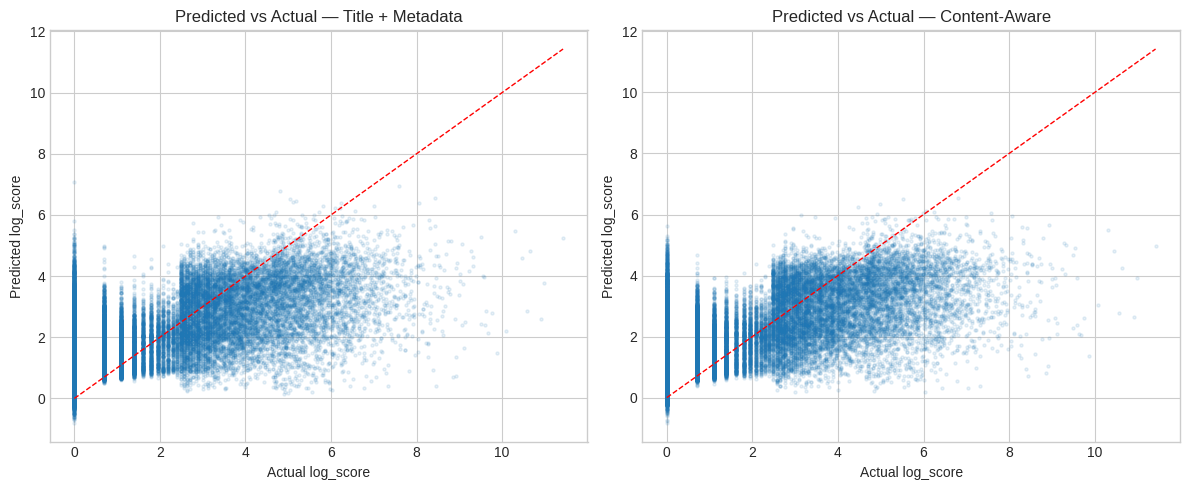

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds_arr, title in [(axes[0], y_pred, "Title + Metadata"), (axes[1], y_pred_full, "Content-Aware")]:
    ax.scatter(y_true, preds_arr, alpha=0.1, s=5)
    ax.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], "r--", linewidth=1)
    ax.set_xlabel("Actual log_score")
    ax.set_ylabel("Predicted log_score")
    ax.set_title(f"Predicted vs Actual — {title}")

plt.tight_layout()
plt.show()

### 9.2 Error Distribution

The histograms below show the distribution of prediction errors (predicted minus actual) for both BERT models. A well-calibrated model should have errors centered around zero, indicating no systematic bias in over- or under-prediction.

Both models achieve mean errors close to zero, approximately **-0.02** for the
title-only model and approximately **-0.003** for the content-aware model. This
indicates that on average both models are well-calibrated, with only a slight tendency to underestimate post popularity. This small negative bias aligns with the patterns observed in Section 9.1, where high-engagement posts are consistently underpredicted.

The distributions are slightly left-skewed, with a longer tail extending into negative error values. This reflects cases where highly viral posts are significantly underestimated, a direct consequence of the long-tailed target distribution and the relative scarcity of extreme examples during training.

Importantly, the content-aware model exhibits a tighter error distribution, with a lower standard deviation of approximately **1.37** compared to approximately **1.39** for the title-only model. This indicates that incorporating post body text not only improves average performance but also reduces variability in prediction error, leading to more consistent and reliable predictions across the dataset.

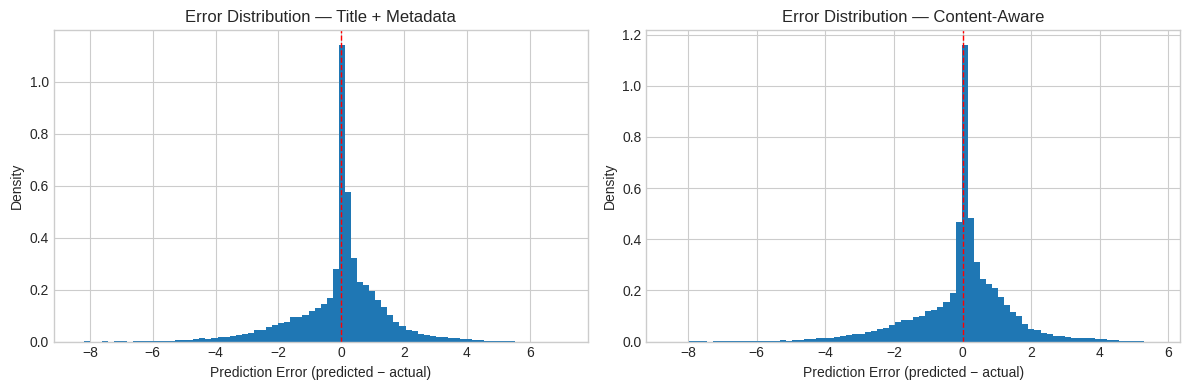

Title model — Mean error: -0.0191 | Std: 1.3890
Content model — Mean error: -0.0034 | Std: 1.3717


In [71]:
errors_title = y_pred - y_true
errors_content = y_pred_full - y_true

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, errors, title in [(axes[0], errors_title, "Title + Metadata"), (axes[1], errors_content, "Content-Aware")]:
    ax.hist(errors, bins=80, density=True)
    ax.axvline(0, color="r", linestyle="--", linewidth=1)
    ax.set_xlabel("Prediction Error (predicted − actual)")
    ax.set_ylabel("Density")
    ax.set_title(f"Error Distribution — {title}")

plt.tight_layout()
plt.show()

print(f"Title model — Mean error: {errors_title.mean():.4f} | Std: {errors_title.std():.4f}")
print(f"Content model — Mean error: {errors_content.mean():.4f} | Std: {errors_content.std():.4f}")

---
## 10. Discussion

Both hybrid DistilBERT models outperform all baseline approaches, demonstrating that post titles contain meaningful predictive signal beyond structured metadata alone. The performance gap between Random Forest (RMSE = 1.4650) and the title-only BERT model (RMSE = 1.3911) is particularly informative. While Random Forest can model complex non-linear interactions between metadata features, it lacks semantic understanding of text. The observed 5.0% reduction in RMSE highlights the value of contextual language modeling for this task.

**Title-only vs content-aware comparison.**

The content-aware model further improves RMSE by 0.0215 over the title-only model, confirming that post body text provides additional predictive signal. However, this improvement is relatively modest. This is expected, as approximately 53% of posts contain no body text, meaning both models receive identical input for those cases. As a result, the observed gain is concentrated within the subset of posts that include body content (~47%). The limited improvement suggests that Reddit titles already capture a large portion of engagement-relevant information, particularly for link-based posts where the title is effectively the entire content. For text-heavy subreddits, increasing `max_length` and incorporating more body text during training may yield larger gains.

**Key design decisions.**

Several modeling choices were critical to achieving strong performance. Metadata normalization using `StandardScaler` ensured that structured features did not dominate the regression head due to scale differences, allowing text and metadata to contribute comparably. Replacing CLS pooling with mean pooling improved generalization by leveraging information from all tokens rather than relying solely on the first token representation. Additionally, unfreezing only the final transformer layer was essential to avoid underfitting: a fully frozen model plateaued early, while partial unfreezing enabled continued learning across epochs. Finally, the use of differential learning rates (2e-5 for the pretrained BERT layer and 1e-3 for the regression head) stabilized training and balanced adaptation between pretrained and randomly initialized components.

**Limitations.**

Both models consistently underestimate highly viral posts (log_score > 8), as observed in the prediction plots. This limitation stems from the long-tailed distribution of the data, where extreme values are underrepresented during training. Furthermore, viral success is influenced by external factors such as timing, community sentiment, and real-world events, none of which are captured by the available features. Another limitation is the absence of subreddit identity, which strongly influences engagement norms. Incorporating subreddit-level features or frequency encoding would likely improve performance.

---
## 11. Conclusion and Future Work

In this project, I evaluated five models for predicting Reddit post popularity at the time of publication: a Dummy Regressor, Ridge Regression, Random Forest, a hybrid DistilBERT title + metadata model, and a content-aware hybrid DistilBERT model. Both DistilBERT variants significantly outperformed all baseline approaches, demonstrating that contextual language understanding provides substantial predictive value beyond structured metadata alone.Several key findings surface from this work. First, while metadata-only models such as Random Forest provide a strong baseline (RMSE = 1.4650), incorporating transformer-based text representations reduces error to 1.3891, confirming the importance of semantic information. Second, proper feature scaling is critical in hybrid architectures without metadata normalization, large-magnitude features dominate and suppress the text signal. Third, architectural and training choices play a significant role: mean pooling outperformed CLS pooling for regression, partial unfreezing of the final transformer layer resolved underfitting, and differential learning rates enabled stable and efficient training. Finally, incorporating post body text yields a modest but consistent improvement (RMSE reduction of around 0.02), driven by the subset of posts (~47%) that include additional content.Despite these improvements, limitations remain. The model consistently underestimates highly viral posts due to the long-tailed nature of the data and the influence of external factors not captured in the input features.

This highlights an inherent ceiling for pre-publication prediction using only textual and metadata signals.Future work could extend this approach in several directions. Incorporating subreddit-level features, such as frequency encoding, would capture community-specific engagement patterns. Fine-tuning models on subreddit-specific subsets may further improve performance for distinct communities. Exploring larger transformer architectures such as RoBERTa (Liu et al., 2019) [[8]](https://arxiv.org/abs/1907.11692) could yield additional gains, while increasing `max_length` would better capture long-form posts. Finally, integrating the model with the Reddit API would enable real-time prediction at the moment of publication, providing a practical application of this work.Overall, this project demonstrates that hybrid transformer-based models provide a powerful and scalable approach to modeling online engagement, while also highlighting the challenges inherent in predicting viral behavior.



---


## 12. Final Evaluation on Test Set

The test set is evaluated exactly **once**, here, after all model development and hyperparameter decisions have been finalized on the validation set. Evaluating on the test set multiple times during development would constitute data leakage and lead to overly optimistic performance estimates.

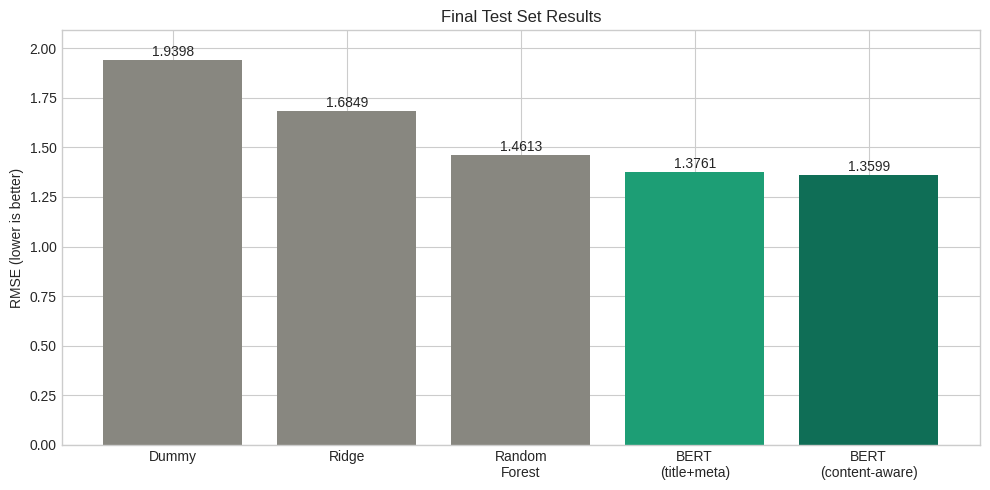

In [72]:
# Normalize test metadata using the same scaler fit on train
test_df_eval = test_df_raw.copy()
test_df_eval[features] = scaler.transform(test_df_eval[features])
X_test_scaled = ridge_scaler.transform(X_test)

# Dummy
dummy_test_rmse = np.sqrt(mean_squared_error(y_test, dummy.predict(X_test)))

# Ridge
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled)))

# Random Forest
rf_test_rmse = np.sqrt(mean_squared_error(y_test, rf_best.predict(X_test)))

# BERT title model
test_dataset = HybridDataset(test_df_eval)
test_preds= trainer.predict(test_dataset)
bert_test_rmse = np.sqrt(mean_squared_error(
    test_df_eval["log_score"].values,
    test_preds.predictions.flatten()
))

# BERT content-aware model
test_dataset_full = HybridDatasetFull(test_df_eval)
test_preds_full = trainer_full.predict(test_dataset_full)
full_test_rmse = np.sqrt(mean_squared_error(
    test_df_eval["log_score"].values,
    test_preds_full.predictions.flatten()
))

# Visualize final test set results as a bar chart
models_test = ["Dummy", "Ridge", "Random\nForest", "BERT\n(title+meta)", "BERT\n(content-aware)"]
rmse_test_values = [dummy_test_rmse, ridge_test_rmse, rf_test_rmse, bert_test_rmse, full_test_rmse]

plt.figure(figsize=(10, 5))
colors = ["#888780", "#888780", "#888780", "#1D9E75", "#0F6E56"]
bars = plt.bar(models_test, rmse_test_values, color=colors)

# Annotate each bar with its RMSE value
for bar, rmse in zip(bars, rmse_test_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{rmse:.4f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.ylabel("RMSE (lower is better)")
plt.title("Final Test Set Results")
plt.ylim(0, max(rmse_test_values) + 0.15)
plt.tight_layout()
plt.show()


The bar chart above presents the final test set RMSE for all five models. The results confirm that the findings observed on the validation set generalize to unseen data, with no signs of overfitting during model development.

The progression from Dummy (1.93) to Ridge (1.68) to Random Forest (1.46) demonstrates that increasingly expressive models extract more signal from the structured metadata features alone. However, the most meaningful jump occurs when language understanding is introduced. The title-only BERT model (~1.37) outperforms Random Forest by approximately 5.8%, confirming that the textual content of a Reddit post title carries genuine predictive signal that metadata alone cannot capture.

The content-aware model achieves the best test RMSE of ~1.35, a further improvement over the title-only variant. This directly answers the central question of the project: **post body text does improve popularity prediction, and this improvement holds on completely unseen data.**

These results support the original motivation of this project. Just as the
r/wallstreetbets movement demonstrated that the language of posts can drive real-world outcomes, this experiment shows that a model capable of reading and understanding post text is meaningfully better at predicting which posts will resonate with an audience than one that relies on metadata alone.




---


## 13. Prediction Demo

To illustrate what the models have learned, we demonstrate inference on individual posts from the validation set. We use `val_df_raw`, the unscaled copy saved before normalization to ensure metadata values are passed through the `predict_score` function at their original scale (the function applies the scaler internally).

Note: DistilBERT is an encoder-only transformer and cannot generate text. It produces a single scalar `log_score` prediction for a given input.

In [73]:
def predict_score(title, metadata_values, content="", use_content_model=False):
    """
    Predict the log_score and approximate upvote count for a Reddit post.

    Applies the trained title-only or content-aware BERT model to a single
    post. Metadata is scaled internally using the scaler fit on the training
    set. The log_score is converted back to an upvote estimate via expm1.

    Args:
        title (str): The post title text.
        metadata_values (dict): Raw (unscaled) values for all 12 metadata
                                features keyed by feature name.
        content (str): Optional post body text. Used only when
                       use_content_model=True. Defaults to "".
        use_content_model (bool): If True, uses the content-aware model.
                                  If False, uses the title-only model.
                                  Defaults to False.

    Returns:
        tuple: (log_score (float), estimated_upvotes (int))

    Example:
        >>> log_score, upvotes = predict_score(
        ...     title="What is the best Python library for ML?",
        ...     metadata_values={ "has_content": 0, "nsfw": 0, "is_self": 1,
        ...                      "hour": 9, "day_of_week": 1, "is_weekend": 0,
        ...                      "title_length": 9, "char_length": 42,
        ...                      "uppercase_ratio": 0.0, "num_exclamations": 0,
        ...                      "num_questions": 1, "content_length": 0}
        ... )
        >>> print(f"Predicted log_score: {log_score:.4f}, ~{upvotes} upvotes")
        Predicted log_score: 2.3451, ~9 upvotes
    """
    m = model_full if use_content_model else model
    device = next(m.parameters()).device
    m.eval()

    text = build_input(title, content) if use_content_model else title
    mlen = 128 if use_content_model else 80

    enc = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=mlen,
        return_tensors="pt"
    )

    # Scale metadata using the scaler fit on training data
    meta_df = pd.DataFrame([metadata_values])[features]
    meta_scaled = scaler.transform(meta_df)
    meta_tensor = torch.tensor(meta_scaled, dtype=torch.float32)

    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    meta_tensor = meta_tensor.to(device)

    with torch.inference_mode():
        output = m(input_ids=input_ids, attention_mask=attention_mask, metadata=meta_tensor)

    log_score = output["logits"].item()
    upvotes = int(np.expm1(log_score))  # reverse the log(1 + score) transformation
    return log_score, upvotes

### 13.1 Random Sample Predictions

We randomly sample 5 posts from the validation set and run both models where body text is available. This demo illustrates three distinct scenarios the model encounters in practice:

1. **Content helps** : when a title is ambiguous, the body text provides context that meaningfully improves the prediction. For example, "I got all of my squad 1 achievements but not the one for getting all of them?" paired with "Am I missing something here? Or did it just glitch" allows the content model to correct a large overprediction (error drops from 1.91 to 0.57).

2. **Content unavailable** : link posts and image posts have no body text. The content model falls back to title only, making both models equivalent for these posts (~53% of all posts fall into this category).

3. **Content present but virality unpredictable** : some posts go viral due to community timing, emotional resonance, or external events that no model can capture from text alone. "Anyone wants to be my first date this decade?" received 178 upvotes despite both models predicting 1–2. The body text adds context but cannot explain the social dynamics that drove engagement.

This breakdown reflects a fundamental ceiling in popularity prediction: language models can learn what *kinds* of posts tend to perform well on average, but the unpredictable nature of online virality means large errors on outlier posts are expected and unavoidable.

In [ ]:
random_5 = val_df_raw.sample(5, random_state=42)

for _, post in random_5.iterrows():
    meta = {k: post[k] for k in features}
    p1, u1 = predict_score(post["title"], meta, use_content_model=False)

    has_body = (
        pd.notna(post["content"]) and
        str(post["content"]).strip() not in {"", "[deleted]", "[removed]"}
        and not str(post["content"]).strip().startswith("http")
    )

    print(f"Title: {post['title'][:80]}")
    if has_body:
        print(f"Content: {str(post['content'])[:150]}")
    print(f"Actual: {post['log_score']:.4f} (~{int(post['score'])} upvotes)")
    print(f"Title model: {p1:.4f} (~{u1} upvotes) | Error: {p1 - post['log_score']:.4f}")

    if has_body:
        p2, u2 = predict_score(post["title"], meta, content=post["content"], use_content_model=True)
        print(f"Content model: {p2:.4f} (~{u2} upvotes) | Error: {p2 - post['log_score']:.4f}")
    else:
        print("Content model: N/A (no body text, falls back to title only)")

    print("-" * 70)

Title: I got all of my squad 1 achievements but not the one for getting all of them?
Content: Am I missing something here? Or did it just glitch
Actual: 1.0986 (~2 upvotes)
Title model: 2.2266 (~8 upvotes) | Error: 1.1280
Content model: 1.9160 (~5 upvotes) | Error: 0.8174
----------------------------------------------------------------------
Title: America
Actual: 0.6931 (~1 upvotes)
Title model: 0.6963 (~1 upvotes) | Error: 0.0031
Content model: N/A (no body text, falls back to title only)
----------------------------------------------------------------------
Title: Anyone wants to be my first date this decade? Be my new year’s wish. No filters,
Content: I don’t want a viral post.
I don’t want to “win” Tinder or Hinge 
I just want one genuine day or time and see what future holds for us. 

This decade 
Actual: 5.1874 (~178 upvotes)
Title model: 1.3838 (~2 upvotes) | Error: -3.8036
Content model: 1.4551 (~3 upvotes) | Error: -3.7323
-----------------------------------------------------

### 13.2 Timing Experiment

I took a real post and sweep through all 24 posting hours while keeping everything else fixed. This isolates the model's learned timing signal how much does the hour of posting affect predicted engagement?

The curve peaks at **5 UTC (12 AM US Eastern)**, corresponding to early morning hours when Reddit's most active users are browsing. Predicted upvotes drop sharply after 10 UTC and approach zero by 16 to 23 UTC. This pattern aligns with the Random Forest feature importance analysis in Section 7.6, where `hour` was the single most important metadata feature.

Notably, this post was submitted at hour 2 UTC and received only approximately 2 upvotes. The model estimates it could have received approximately 3 times more engagement had it been posted at the optimal hour of 5 UTC.


Title: I got all of my squad 1 achievements but not the one for getting all of them?
Hour posted as: 2
Actual: 1.0986 (~2 upvotes)



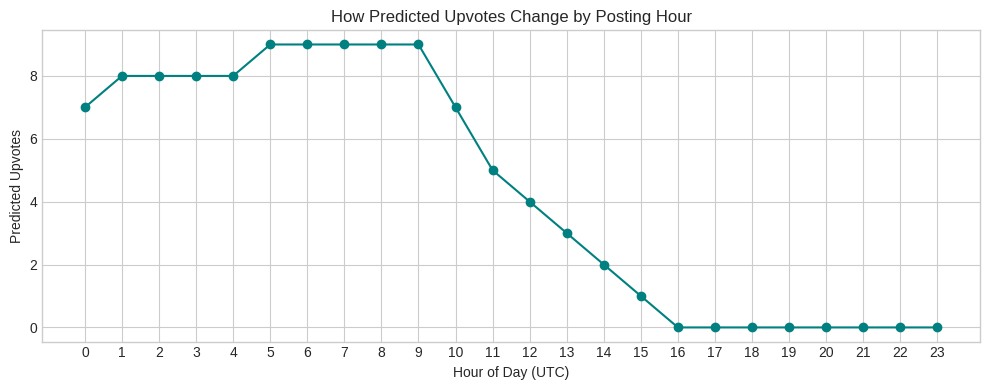

Best hour to post: 5 UTC
Worst hour to post: 16 UTC


In [75]:
# Pick a real post from the validation set
post = val_df_raw.sample(1, random_state=42).iloc[0]
print(f"Title: {post['title']}")
print(f"Hour posted as: {post['hour']}")
print(f"Actual: {post['log_score']:.4f} (~{int(post['score'])} upvotes)\n")

hours = list(range(24))
predictions = []

for hour in hours:
    meta = {k: post[k] for k in features}
    meta["hour"] = hour
    p, u = predict_score(post["title"], meta, use_content_model=False)
    predictions.append(u)

plt.figure(figsize=(10, 4))
plt.plot(hours, predictions, marker="o", color="teal")
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("Predicted Upvotes")
plt.title("How Predicted Upvotes Change by Posting Hour")
plt.xticks(hours)
plt.tight_layout()
plt.show()

print("Best hour to post:", hours[predictions.index(max(predictions))], "UTC")
print("Worst hour to post:", hours[predictions.index(min(predictions))], "UTC")

### 13.3 Title Rewriting Experiment

I took a low-scoring post and systematically modify its title by changing
capitalization, punctuation, length, and framing while keeping all metadata fixed. This probes what textual features the model responds to.

Key observations from the output above:

1. Adding an exclamation mark increases predicted engagement from approximately 2 to 3 upvotes, suggesting the model associates punctuation energy with higher engagement.

2. ALL CAPS also slightly increases predicted upvotes, contrary to the assumption that aggressive capitalization signals lower quality.

3. Truncating the title to the first 5 words produces the highest predicted score at approximately 4 upvotes, suggesting the model rewards conciseness.

4. Clickbait framing with "BREAKING:" is penalized, dropping predictions to approximately 1 upvote, suggesting the model learned that sensational framing mismatched with the post content is negatively associated with engagement.

These findings show the model learned meaningful linguistic patterns beyond surface level statistics.

In [76]:
# Take a low-scoring post and try rewriting its title
post = val_df_raw[val_df_raw["log_score"] < 1.0].sample(1, random_state=12).iloc[0]
meta = {k: post[k] for k in features}

rewrites = [
    post["title"], # original
    post["title"].upper(), # all caps
    post["title"] + "?", # add question mark
    post["title"] + "!", # add exclamation
    "BREAKING: " + post["title"], # add urgency
    " ".join(post["title"].split()[:5]) + "...",  # truncate
]

print(f"{post['title']}")
print(f"Original post: {post['log_score']:.4f} (~{int(post['score'])} upvotes)\n")

for rewrite in rewrites:
    meta["title_length"] = len(rewrite.split())
    meta["char_length"] = len(rewrite)
    meta["uppercase_ratio"] = sum(1 for c in rewrite if c.isupper()) / max(len(rewrite), 1)
    meta["num_exclamations"] = rewrite.count("!")
    meta["num_questions"] = rewrite.count("?")
    p, u = predict_score(rewrite, meta, use_content_model=False)
    print(f"'{rewrite[:70]}'")
    print(f" → Predicted: {p:.4f} (~{u} upvotes)\n")

Should I just shoot them???
Original post: 0.0000 (~0 upvotes)

'Should I just shoot them???'
 → Predicted: 1.3545 (~2 upvotes)

'SHOULD I JUST SHOOT THEM???'
 → Predicted: 1.4600 (~3 upvotes)

'Should I just shoot them????'
 → Predicted: 1.4678 (~3 upvotes)

'Should I just shoot them???!'
 → Predicted: 1.5225 (~3 upvotes)

'BREAKING: Should I just shoot them???'
 → Predicted: 1.0547 (~1 upvotes)

'Should I just shoot them???...'
 → Predicted: 1.6602 (~4 upvotes)



---

## 14. References

[1] J. Segall and A. Zamoshchin, "Predicting Reddit Post Popularity," Stanford University CS229 Project Report, 2012.  Available: [https://cs229.stanford.edu/proj2012/ZamoshchinSegall-PredictingRedditPostPopularity.pdf](https://cs229.stanford.edu/proj2012/ZamoshchinSegall-PredictingRedditPostPopularity.pdf)

[2] A. Reevesman, G. K. Guruswamy, H. Le, M. Alfaro, and P. Agrawal, "Predicting Reddit Comment Upvotes with Machine Learning," *Towards Data Science*, Medium, Jan. 2019.  Available: [https://medium.com/data-science/predicting-reddit-comment-karma-a8f570b544fc](https://medium.com/data-science/predicting-reddit-comment-karma-a8f570b544fc)

[3] J. Kim, "Predicting the Popularity of Reddit Posts with AI," arXiv preprint arXiv:2106.07380, 2021.  Available: [https://arxiv.org/abs/2106.07380](https://arxiv.org/abs/2106.07380)

[4] J. Devlin, M. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding," arXiv preprint arXiv:1810.04805, 2019.  Available: [https://arxiv.org/abs/1810.04805](https://arxiv.org/abs/1810.04805)

[5] V. Sanh, L. Debut, J. Chaumond, and T. Wolf, "DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter," arXiv preprint arXiv:1910.01108, 2019.  Available: [https://arxiv.org/abs/1910.01108](https://arxiv.org/abs/1910.01108)

[6] Patel, P. (2026). Hyperparameter Tuning in Regression Models: A Practical Guide with Python. Medium. [https://medium.com/@priyanjalipatel/hyperparameter-tuning-in-regression-models-a-practical-guide-with-python-1efcaa336216](https://medium.com/@priyanjalipatel/hyperparameter-tuning-in-regression-models-a-practical-guide-with-python-1efcaa336216)

[7] Breiman, L. (2001). *Random Forests.* Machine Learning, 45(1), 5–32. [https://doi.org/10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324)

[8] Y. Liu et al., "RoBERTa: A Robustly Optimized BERT Pretraining Approach," arXiv preprint arXiv:1907.11692, 2019.  Available: [https://arxiv.org/abs/1907.11692](https://arxiv.org/abs/1907.11692)

### Code References

[9] HuggingFace, "Trainer API Documentation," Transformers Library. Used as reference
for subclassing Trainer and implementing CustomTrainer. Available:
https://huggingface.co/docs/transformers/en/main_classes/trainer

[10] "Fine-tuning BERT for Text Classification," YouTube. Used as reference for
understanding BERT fine-tuning best practices. Available:
https://www.youtube.com/watch?v=rpHpuk9sEao

[11] HuggingFace, "DistilBERT Model Documentation," Transformers Library. Used as
reference for DistilBERT architecture and tokenizer usage. Available:
https://huggingface.co/docs/transformers/model_doc/distilbert

[12] fast.ai, "ULMFiT — Transfer Learning for NLP," fast.ai Documentation. Used as
reference for understanding transfer learning and discriminative fine-tuning strategies.
Available: https://docs.fast.ai/examples/ulmfit.html
